# Adaptive Temporal Detection of Denial-of-Wallet Attacks

## Notebook 01 — Data Preparation and Temporal Sequence Construction

This notebook performs:

1. Dataset smoke testing and schema verification.
2. Data quality assessment, including missing values, duplicates, invalid records and class distribution.
3. Timestamp parsing and chronological ordering of workload observations.
4. Temporal workload feature engineering, including invocation frequency, inter-arrival time, execution duration and rolling invocation statistics.
5. FunctionId-disjoint training, validation and testing splits to prevent functions from overlapping across datasets.
6. Numerical and categorical feature preparation, with preprocessing fitted on training data only.
7. Temporal sequence construction using 30-timestep sliding windows within each function, with recording-gap handling.
8. Verification of binary class distribution, sequence dimensions, numerical integrity and structural data-leakage checks.
9. Saving processed datasets, encoded feature names, sequence arrays, preprocessing artifacts and metadata for LSTM, GRU and TCN modelling.

**Evaluation Strategy:** The dataset uses FunctionId-disjoint supervised binary classification. Chronological ordering is preserved within each function, but the partitions are not globally chronological.

In [1]:
import os
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report

import joblib

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
from pathlib import Path

PROJECT_ROOT = Path(".")

RAW_DIR = PROJECT_ROOT / "data" / "raw"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = PROJECT_ROOT / "models"

for directory in [
    RAW_DIR,
    INTERIM_DIR,
    PROCESSED_DIR,
    RESULTS_DIR,
    MODELS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

DATA_PATH = RAW_DIR / "dataset.csv"

print("Current working directory:", Path.cwd())
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

Current working directory: c:\MATT PROJECT\DoW Serverless Project
Dataset path: data\raw\dataset.csv
Dataset exists: True


In [3]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully.
Shape: (187087, 19)


,Id,IP,bot,FunctionId,functionTrigger,timestamp,SubmitTime,RTT,InvocationDelay,ResponseDelay,FunctionDuration,ActiveFunctionsAtRequest,ActiveFunctionsAtResponse,maxcpu,avgcpu,p95maxcpu,vmcategory,vmcorecountbucket,vmmemorybucket
0,0,38.57.146.249,True,12,notification,2022-01-02T03:31:34.498Z,73,2616,1416.003662,154.615479,1045.380831,12,999,100.0,19.867088,97.914746,Delay-insensitive,8,56.0
1,1,55.220.132.116,True,12,notification,2022-01-02T03:54:53.136Z,73,2616,1416.003662,154.615479,1045.380831,12,999,100.0,19.867088,97.914746,Delay-insensitive,8,56.0
2,2,141.232.38.48,True,12,notification,2022-01-02T03:38:31.950Z,73,2616,1416.003662,154.615479,1045.380831,12,999,100.0,19.867088,97.914746,Delay-insensitive,8,56.0
3,3,228.143.56.163,True,12,notification,2022-01-02T03:44:36.548Z,73,2616,1416.003662,154.615479,1045.380831,12,999,100.0,19.867088,97.914746,Delay-insensitive,8,56.0
4,4,223.113.21.186,True,12,notification,2022-01-02T03:52:54.326Z,73,2616,1416.003662,154.615479,1045.380831,12,999,100.0,19.867088,97.914746,Delay-insensitive,8,56.0


In [4]:
print("Number of rows   :", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumns:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i:02d}. {column}")

Number of rows   : 187087
Number of columns: 19

Columns:
01. Id
02. IP
03. bot
04. FunctionId
05. functionTrigger
06. timestamp
07. SubmitTime
08. RTT
09. InvocationDelay
10. ResponseDelay
11. FunctionDuration
12. ActiveFunctionsAtRequest
13. ActiveFunctionsAtResponse
14. maxcpu
15. avgcpu
16. p95maxcpu
17. vmcategory
18. vmcorecountbucket
19. vmmemorybucket


In [5]:
dtype_report = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values
})

dtype_report

,Column,Data_Type
0,Id,int64
1,IP,str
2,bot,bool
3,FunctionId,int64
4,functionTrigger,str
5,timestamp,str
6,SubmitTime,int64
7,RTT,int64
8,InvocationDelay,float64
9,ResponseDelay,float64


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 187087 entries, 0 to 187086
Data columns (total 19 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   Id                         187087 non-null  int64  
 1   IP                         187087 non-null  str    
 2   bot                        187087 non-null  bool   
 3   FunctionId                 187087 non-null  int64  
 4   functionTrigger            187087 non-null  str    
 5   timestamp                  187087 non-null  str    
 6   SubmitTime                 187087 non-null  int64  
 7   RTT                        187087 non-null  int64  
 8   InvocationDelay            187087 non-null  float64
 9   ResponseDelay              187087 non-null  float64
 10  FunctionDuration           187087 non-null  float64
 11  ActiveFunctionsAtRequest   187087 non-null  int64  
 12  ActiveFunctionsAtResponse  187087 non-null  int64  
 13  maxcpu                     187087 non-nu

In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,187087.0,NaN,NaN,NaN,93543.0,54007.509243,0.0,46771.5,93543.0,140314.5,187086.0
IP,187087,7587,158.135.184.38,2159,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bot,187087,2,True,131072,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FunctionId,187087.0,NaN,NaN,NaN,28.592569,13.777358,2.0,17.0,30.0,40.0,50.0
functionTrigger,187087,5,notification,58199,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,187087,186696,2022-01-01T02:13:28.962Z,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SubmitTime,187087.0,NaN,NaN,NaN,85.84125,11.968575,71.0,75.0,79.0,98.0,102.0
RTT,187087.0,NaN,NaN,NaN,2494.167083,286.236688,1373.0,2344.0,2476.0,2593.0,3019.0
InvocationDelay,187087.0,NaN,NaN,NaN,1239.287586,299.874337,170.746338,1060.574707,1205.249512,1388.304443,1800.190674
ResponseDelay,187087.0,NaN,NaN,NaN,165.658396,42.83826,117.803711,134.759521,145.178711,203.505127,247.116455


In [8]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_report = missing_report.sort_values(
    "Missing_Count",
    ascending=False
)

missing_report

,Missing_Count,Missing_Percentage
Id,0,0.0
IP,0,0.0
bot,0,0.0
FunctionId,0,0.0
functionTrigger,0,0.0
timestamp,0,0.0
SubmitTime,0,0.0
RTT,0,0.0
InvocationDelay,0,0.0
ResponseDelay,0,0.0


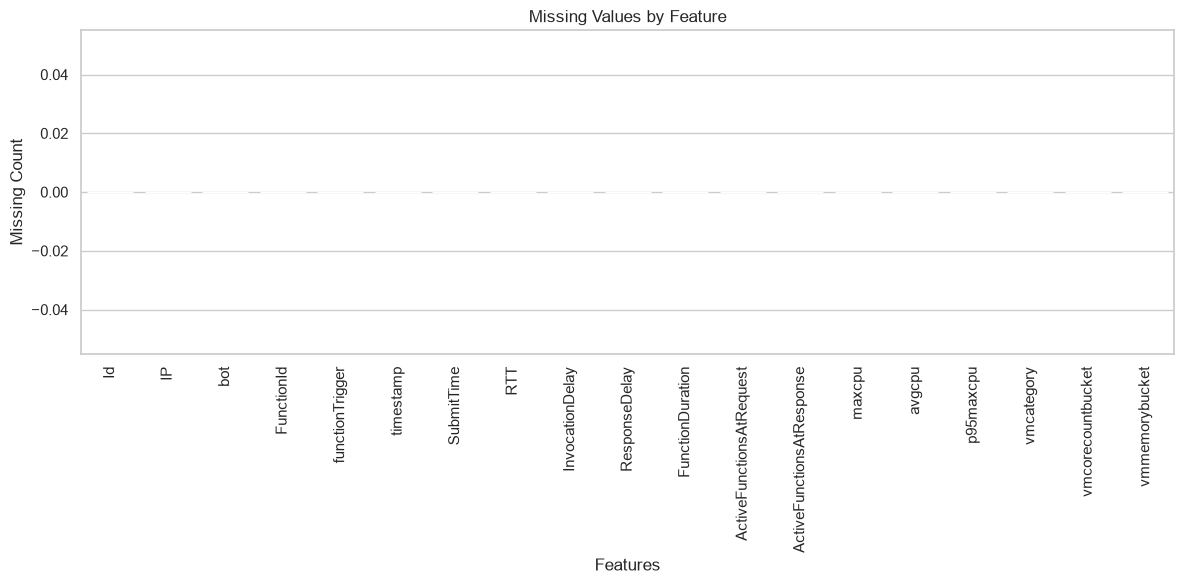

In [9]:
plt.figure(figsize=(12, 6))

missing_plot = (
    df.isnull()
      .sum()
      .sort_values(ascending=False)
)

sns.barplot(
    x=missing_plot.index,
    y=missing_plot.values
)

plt.title("Missing Values by Feature")
plt.xlabel("Features")
plt.ylabel("Missing Count")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [10]:
duplicate_count = df.duplicated().sum()

print("Number of duplicated rows:", duplicate_count)
print(
    "Duplicate percentage:",
    round((duplicate_count / len(df)) * 100, 4),
    "%"
)

Number of duplicated rows: 0
Duplicate percentage: 0.0 %


In [11]:
unique_report = pd.DataFrame({
    "Column": df.columns,
    "Unique_Values": [df[col].nunique(dropna=False) for col in df.columns]
})

unique_report.sort_values("Unique_Values")

,Column,Unique_Values
2,bot,2
17,vmcorecountbucket,2
16,vmcategory,3
18,vmmemorybucket,3
4,functionTrigger,5
12,ActiveFunctionsAtResponse,9
6,SubmitTime,18
7,RTT,37
13,maxcpu,43
11,ActiveFunctionsAtRequest,45


Verify Target Column

In [12]:
print("Target column: bot")

print("\nTarget unique values:")
print(df["bot"].unique())

print("\nTarget class counts:")
print(df["bot"].value_counts())

print("\nTarget percentages:")
print(
    df["bot"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Target column: bot

Target unique values:
[ True False]

Target class counts:
bot
True     131072
False     56015
Name: count, dtype: int64

Target percentages:
bot
True     70.06
False    29.94
Name: proportion, dtype: float64


Target Class Distribution Plot

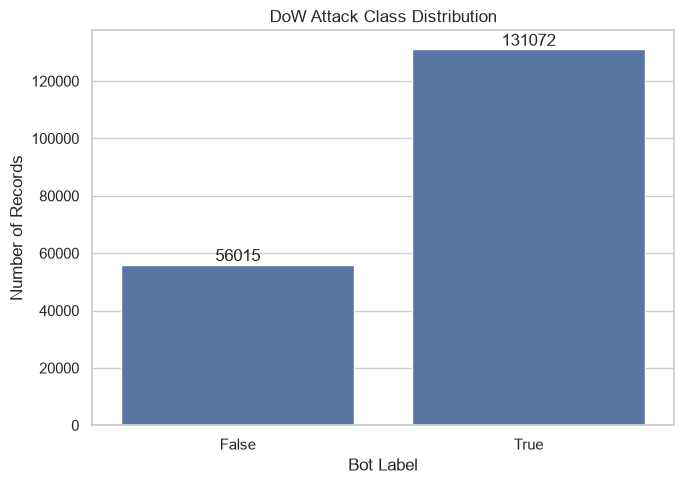

In [13]:
target_counts = df["bot"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=target_counts.index.astype(str),
    y=target_counts.values
)

plt.title("DoW Attack Class Distribution")
plt.xlabel("Bot Label")
plt.ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

Target Percentage Plot

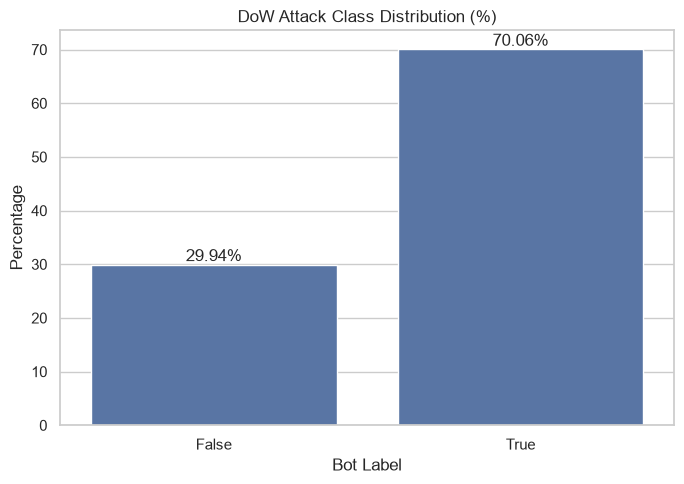

In [14]:
target_percentage = (
    df["bot"]
    .value_counts(normalize=True)
    .mul(100)
    .sort_index()
)

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=target_percentage.index.astype(str),
    y=target_percentage.values
)

plt.title("DoW Attack Class Distribution (%)")
plt.xlabel("Bot Label")
plt.ylabel("Percentage")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.tight_layout()
plt.show()

Inspect Categorical Columns

In [15]:
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

Categorical columns:
['IP', 'bot', 'functionTrigger', 'timestamp', 'vmcategory']


Function Trigger Distribution

functionTrigger
notification    58199
sql             44176
http            32293
storage         31064
stream          21355
Name: count, dtype: int64


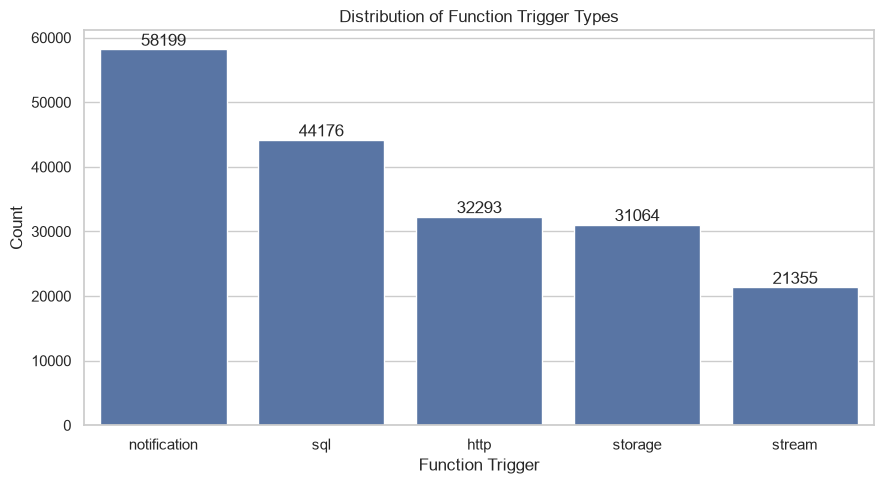

In [16]:
print(df["functionTrigger"].value_counts())

plt.figure(figsize=(9, 5))

order = df["functionTrigger"].value_counts().index

ax = sns.countplot(
    data=df,
    x="functionTrigger",
    order=order
)

plt.title("Distribution of Function Trigger Types")
plt.xlabel("Function Trigger")
plt.ylabel("Count")

plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

VM Category Distribution

vmcategory
Delay-insensitive    73602
Unkown               57157
Interactive          56328
Name: count, dtype: int64


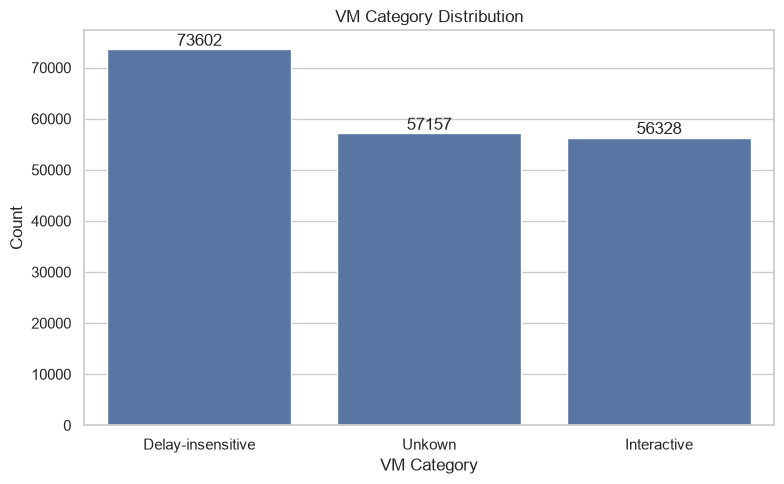

In [17]:
print(df["vmcategory"].value_counts())

plt.figure(figsize=(8, 5))

order = df["vmcategory"].value_counts().index

ax = sns.countplot(
    data=df,
    x="vmcategory",
    order=order
)

plt.title("VM Category Distribution")
plt.xlabel("VM Category")
plt.ylabel("Count")

plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

Check Numeric Ranges

In [18]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

range_report = pd.DataFrame({
    "Feature": numeric_columns,
    "Minimum": [df[col].min() for col in numeric_columns],
    "Maximum": [df[col].max() for col in numeric_columns],
    "Mean": [df[col].mean() for col in numeric_columns],
    "Std": [df[col].std() for col in numeric_columns]
})

range_report

,Feature,Minimum,Maximum,Mean,Std
0,Id,0.000000,187086.000000,93543.000000,54007.509243
1,FunctionId,2.000000,50.000000,28.592569,13.777358
2,SubmitTime,71.000000,102.000000,85.841250,11.968575
3,RTT,1373.000000,3019.000000,2494.167083,286.236688
4,InvocationDelay,170.746338,1800.190674,1239.287586,299.874337
5,ResponseDelay,117.803711,247.116455,165.658396,42.838260
6,FunctionDuration,1031.168938,1437.139511,1089.373666,62.326101
7,ActiveFunctionsAtRequest,2.000000,50.000000,28.592569,13.777358
8,ActiveFunctionsAtResponse,988.000000,999.000000,996.465741,3.010734
9,maxcpu,78.776399,100.000000,97.050470,5.018163


Numeric Feature Distributions

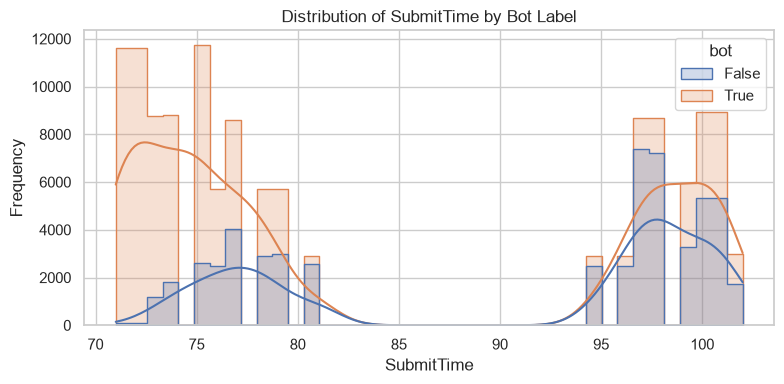

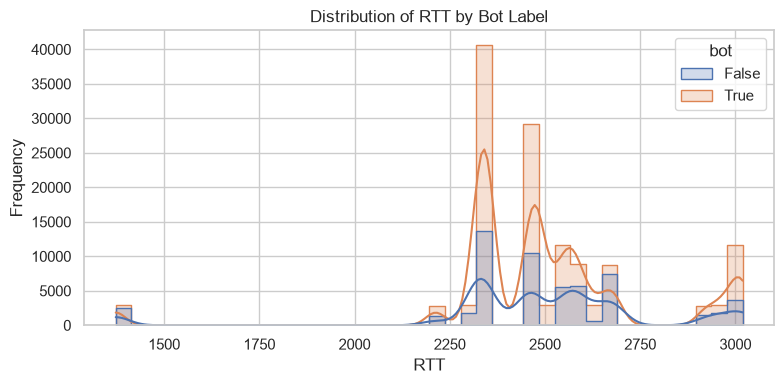

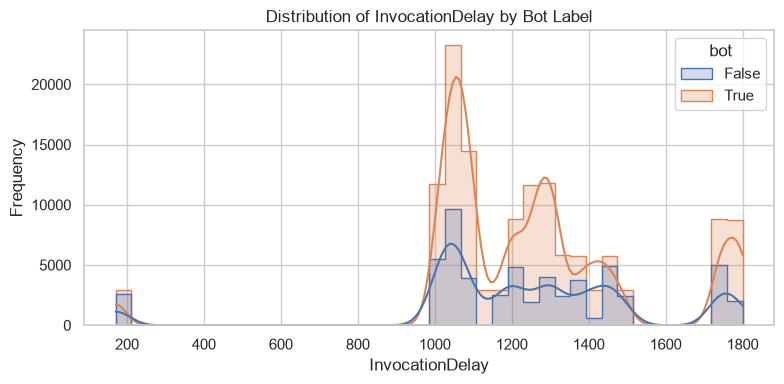

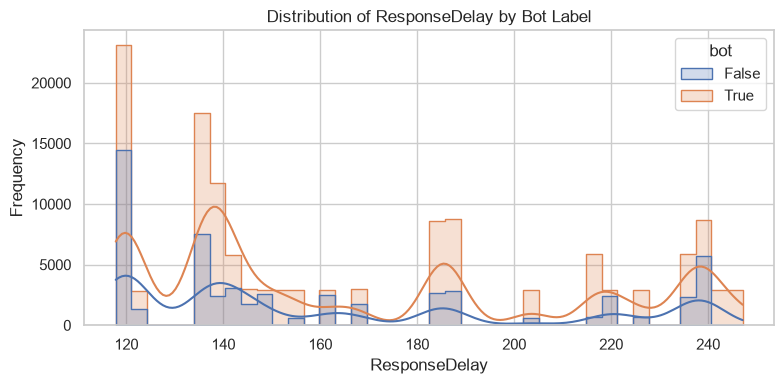

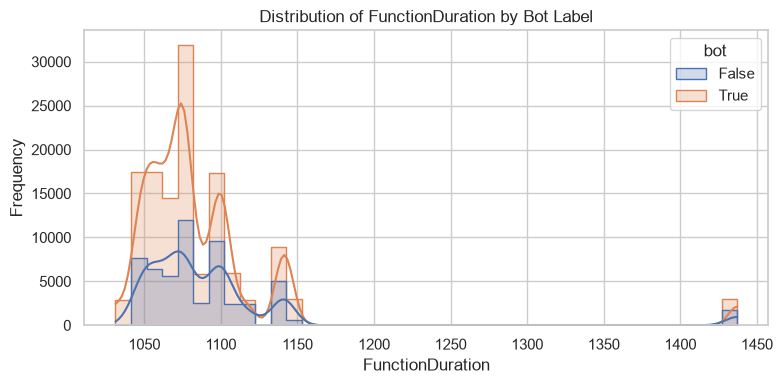

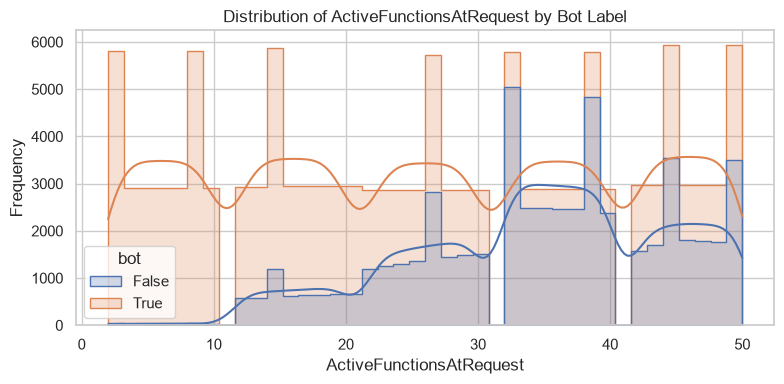

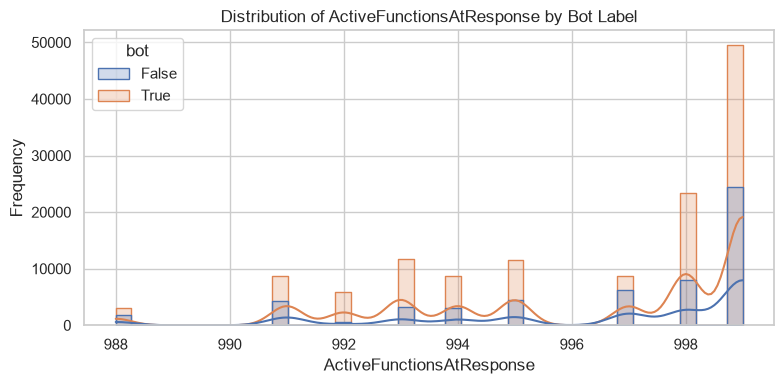

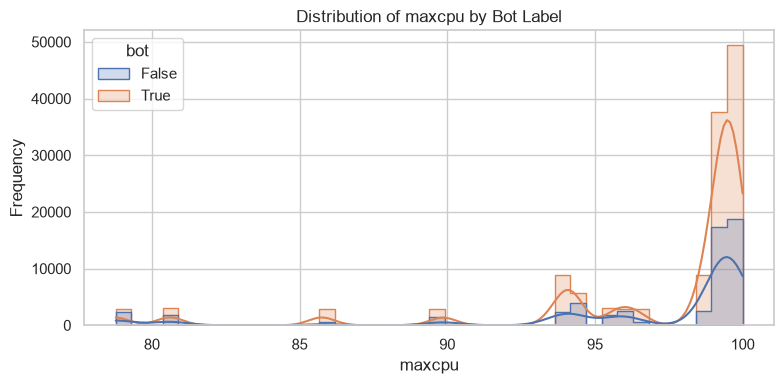

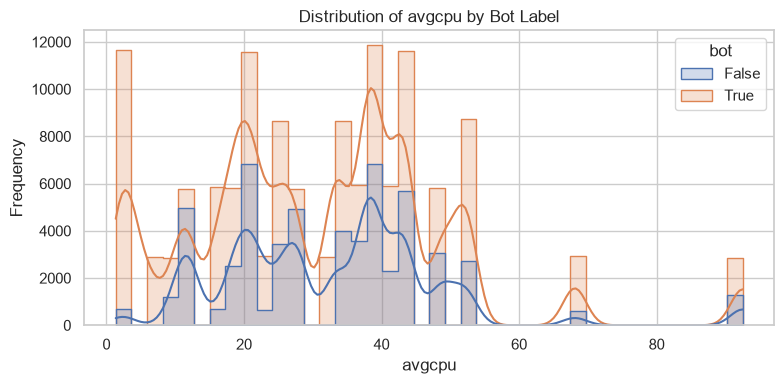

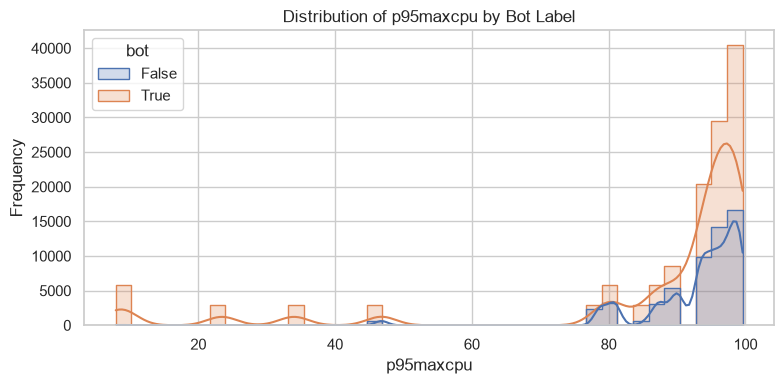

In [19]:
important_numeric_features = [
    "SubmitTime",
    "RTT",
    "InvocationDelay",
    "ResponseDelay",
    "FunctionDuration",
    "ActiveFunctionsAtRequest",
    "ActiveFunctionsAtResponse",
    "maxcpu",
    "avgcpu",
    "p95maxcpu"
]

for column in important_numeric_features:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=column,
        hue="bot",
        bins=40,
        kde=True,
        element="step"
    )

    plt.title(f"Distribution of {column} by Bot Label")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

Correlation Matrix

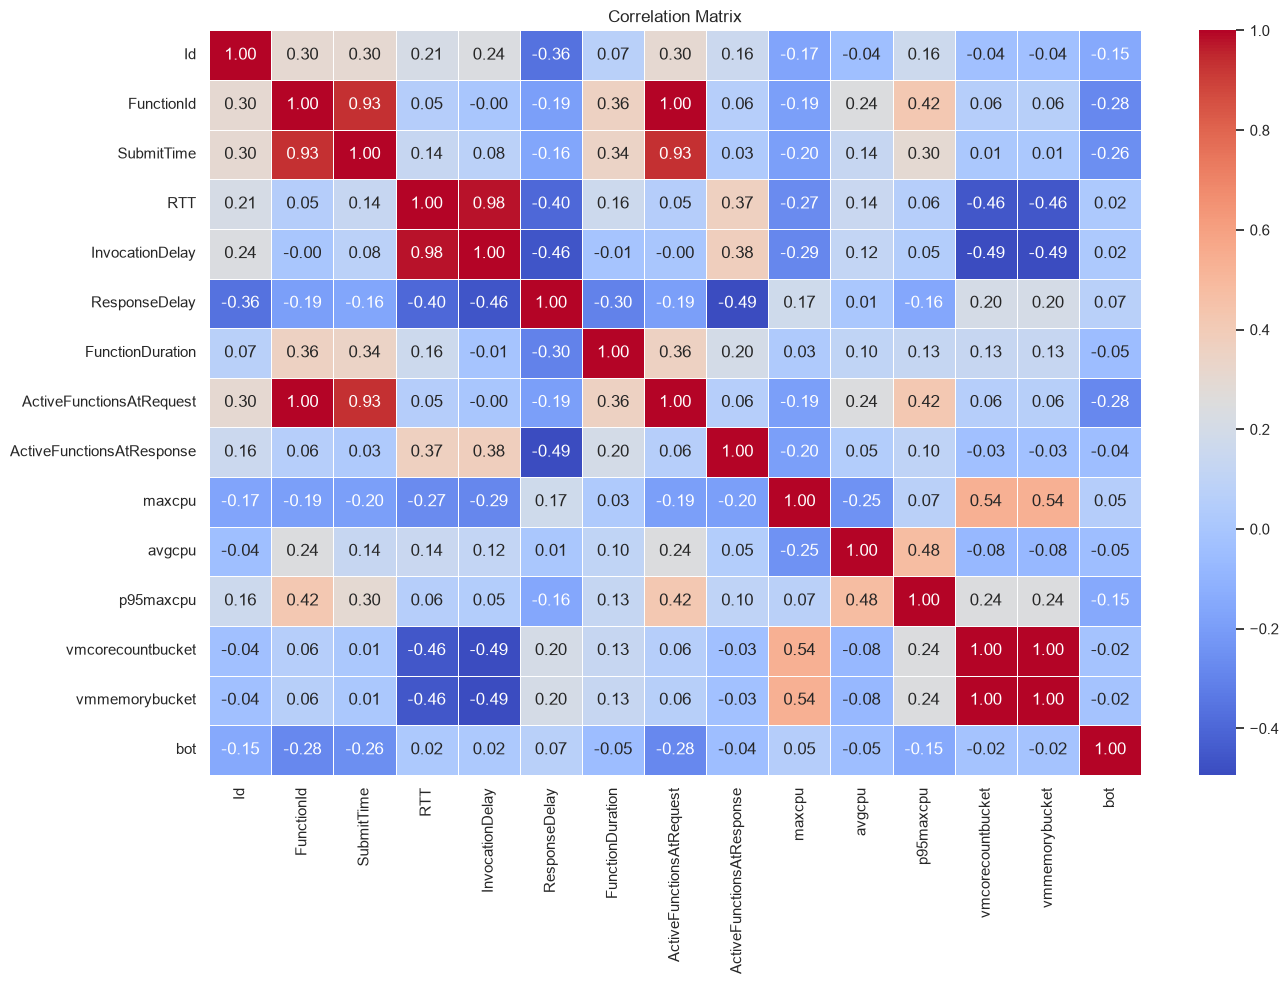

In [20]:
corr_df = df.select_dtypes(include=np.number).copy()

corr_df["bot"] = df["bot"].astype(int)

correlation_matrix = corr_df.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Matrix")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Creating Working Copy

In [21]:
work_df = df.copy()

print("Working dataframe created.")
print(work_df.shape)

Working dataframe created.
(187087, 19)


Converting Target to Integer

In [22]:
work_df["bot"] = work_df["bot"].astype(int)

print(work_df["bot"].value_counts())
print(work_df["bot"].dtype)

bot
1    131072
0     56015
Name: count, dtype: int64
int64


Parse Timestamp

In [23]:
work_df["timestamp_original"] = work_df["timestamp"]

work_df["timestamp"] = pd.to_datetime(
    work_df["timestamp"],
    errors="coerce",
    utc=True
)

print("Invalid timestamps:", work_df["timestamp"].isna().sum())

print("\nTimestamp range:")
print("Start:", work_df["timestamp"].min())
print("End  :", work_df["timestamp"].max())

Invalid timestamps: 1

Timestamp range:
Start: 2022-01-01 01:00:08.316000+00:00
End  : 2022-01-02 17:59:37.586000+00:00


Robust Timestamp Repair


In [24]:
timestamp_invalid = work_df["timestamp"].isna()

print(
    "Timestamps requiring fallback parsing:",
    timestamp_invalid.sum()
)

if timestamp_invalid.any():

    fallback_timestamp = pd.to_datetime(
        work_df.loc[timestamp_invalid, "timestamp_original"],
        errors="coerce",
        utc=True,
        format="mixed"
    )

    work_df.loc[
        timestamp_invalid,
        "timestamp"
    ] = fallback_timestamp

print(
    "Invalid timestamps after fallback:",
    work_df["timestamp"].isna().sum()
)

Timestamps requiring fallback parsing: 1
Invalid timestamps after fallback: 0


Removing Only Truly Invalid Timestamps

In [25]:
before = len(work_df)

work_df = work_df.dropna(
    subset=["timestamp"]
).copy()

after = len(work_df)

print("Rows before:", before)
print("Rows after :", after)
print("Rows removed:", before - after)

Rows before: 187087
Rows after : 187087
Rows removed: 0


Chronological Sorting

In [26]:
work_df = (
    work_df
    .sort_values(["timestamp", "Id"])
    .reset_index(drop=True)
)

print("Chronological sorting completed.")

work_df[
    ["Id", "timestamp", "bot"]
].head(10)

Chronological sorting completed.


,Id,timestamp,bot
0,48323,2022-01-01 01:00:08.316000+00:00,0
1,158030,2022-01-01 01:00:09.164000+00:00,0
2,168786,2022-01-01 01:00:09.242000+00:00,0
3,163447,2022-01-01 01:00:09.984000+00:00,0
4,174133,2022-01-01 01:00:10.377000+00:00,0
5,76025,2022-01-01 01:00:10.463000+00:00,0
6,179450,2022-01-01 01:00:10.971000+00:00,0
7,81431,2022-01-01 01:00:11.315000+00:00,0
8,184745,2022-01-01 01:00:12.007000+00:00,0
9,168927,2022-01-01 01:00:12.175000+00:00,0


Verify Chronological Order

In [27]:
is_chronological = work_df["timestamp"].is_monotonic_increasing

print(
    "Dataset chronologically ordered:",
    is_chronological
)

Dataset chronologically ordered: True


Timestamp Range

In [28]:
print(
    "Beginning timestamp:",
    work_df["timestamp"].min()
)

print(
    "Ending timestamp:",
    work_df["timestamp"].max()
)

print(
    "Observed duration:",
    work_df["timestamp"].max()
    - work_df["timestamp"].min()
)

Beginning timestamp: 2022-01-01 01:00:08.316000+00:00
Ending timestamp: 2022-01-02 17:59:37.586000+00:00
Observed duration: 1 days 16:59:29.270000


Plot Events Over Time

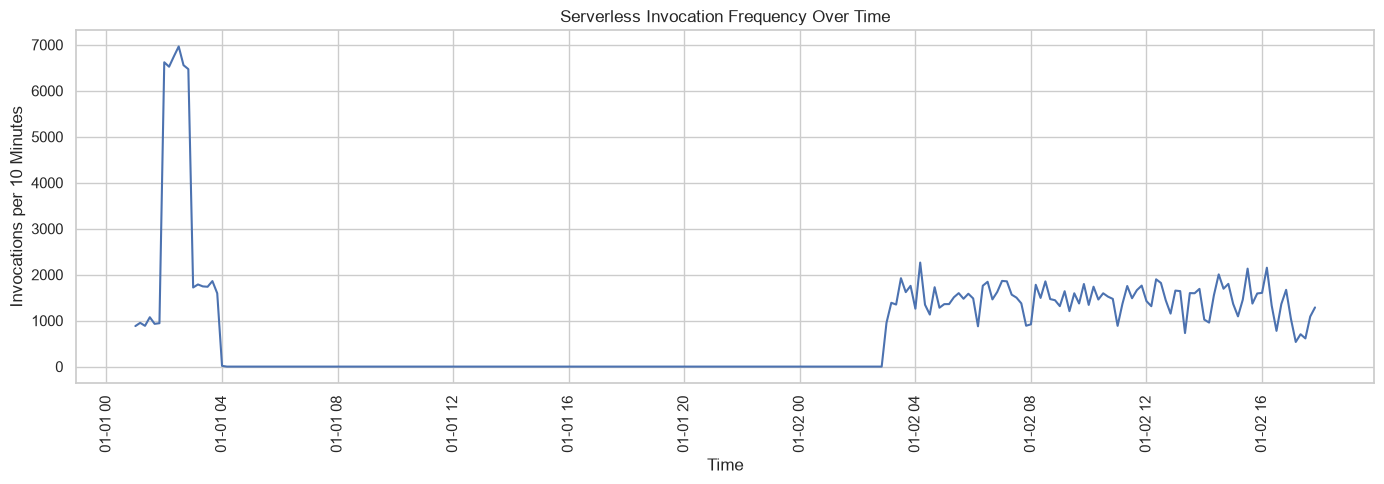

In [29]:
timeline_df = (
    work_df
    .set_index("timestamp")
    .resample("10min")
    .size()
    .rename("Invocation_Count")
    .reset_index()
)

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=timeline_df,
    x="timestamp",
    y="Invocation_Count"
)

plt.title("Serverless Invocation Frequency Over Time")
plt.xlabel("Time")
plt.ylabel("Invocations per 10 Minutes")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

Attack Activity Over Time

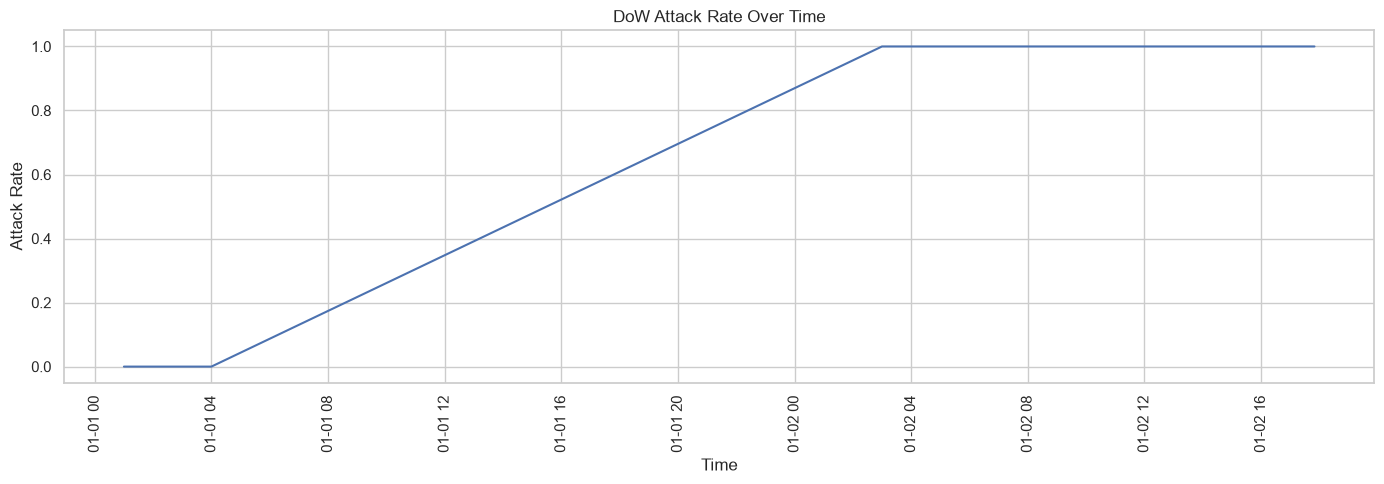

In [30]:
attack_timeline = (
    work_df
    .set_index("timestamp")["bot"]
    .resample("10min")
    .agg(["count", "sum"])
    .reset_index()
)

attack_timeline["Attack_Rate"] = (
    attack_timeline["sum"]
    / attack_timeline["count"]
)

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=attack_timeline,
    x="timestamp",
    y="Attack_Rate"
)

plt.title("DoW Attack Rate Over Time")
plt.xlabel("Time")
plt.ylabel("Attack Rate")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

Basic Time Features

In [31]:
work_df["hour"] = work_df["timestamp"].dt.hour
work_df["minute"] = work_df["timestamp"].dt.minute
work_df["second"] = work_df["timestamp"].dt.second

work_df["day_of_week"] = work_df["timestamp"].dt.dayofweek

work_df["elapsed_seconds"] = (
    work_df["timestamp"]
    - work_df["timestamp"].min()
).dt.total_seconds()

work_df[
    [
        "timestamp",
        "hour",
        "minute",
        "second",
        "day_of_week",
        "elapsed_seconds"
    ]
].head()

,timestamp,hour,minute,second,day_of_week,elapsed_seconds
0,2022-01-01 01:00:08.316000+00:00,1,0,8,5,0.000
1,2022-01-01 01:00:09.164000+00:00,1,0,9,5,0.848
2,2022-01-01 01:00:09.242000+00:00,1,0,9,5,0.926
3,2022-01-01 01:00:09.984000+00:00,1,0,9,5,1.668
4,2022-01-01 01:00:10.377000+00:00,1,0,10,5,2.061


Inter-Arrival Time

In [32]:

# Function-specific causal inter-arrival time

work_df = work_df.sort_values(
    ["timestamp", "Id"]
).reset_index(drop=True)

work_df["InterArrivalTime"] = (
    work_df.groupby("FunctionId")["timestamp"]
    .diff()
    .dt.total_seconds()
    .fillna(0)
)

assert (work_df["InterArrivalTime"] >= 0).all()

display(
    work_df[
        ["FunctionId", "timestamp", "InterArrivalTime"]
    ].head(10)
)


,FunctionId,timestamp,InterArrivalTime
0,32,2022-01-01 01:00:08.316000+00:00,0.000
1,33,2022-01-01 01:00:09.164000+00:00,0.000
2,37,2022-01-01 01:00:09.242000+00:00,0.000
3,34,2022-01-01 01:00:09.984000+00:00,0.000
4,38,2022-01-01 01:00:10.377000+00:00,0.000
5,35,2022-01-01 01:00:10.463000+00:00,0.000
6,39,2022-01-01 01:00:10.971000+00:00,0.000
7,36,2022-01-01 01:00:11.315000+00:00,0.000
8,40,2022-01-01 01:00:12.007000+00:00,0.000
9,37,2022-01-01 01:00:12.175000+00:00,2.933


Invocation Frequency

In [33]:

# Function-specific invocation frequency within each minute

work_df = work_df.sort_values(
    ["timestamp", "Id"]
).reset_index(drop=True)

work_df["time_minute"] = (
    work_df["timestamp"].dt.floor("min")
)

work_df["InvocationsPerMinute"] = (
    work_df.groupby(
        ["FunctionId", "time_minute"]
    ).cumcount() + 1
)

display(
    work_df[
        ["FunctionId", "timestamp", "InvocationsPerMinute"]
    ].head(10)
)


,FunctionId,timestamp,InvocationsPerMinute
0,32,2022-01-01 01:00:08.316000+00:00,1
1,33,2022-01-01 01:00:09.164000+00:00,1
2,37,2022-01-01 01:00:09.242000+00:00,1
3,34,2022-01-01 01:00:09.984000+00:00,1
4,38,2022-01-01 01:00:10.377000+00:00,1
5,35,2022-01-01 01:00:10.463000+00:00,1
6,39,2022-01-01 01:00:10.971000+00:00,1
7,36,2022-01-01 01:00:11.315000+00:00,1
8,40,2022-01-01 01:00:12.007000+00:00,1
9,37,2022-01-01 01:00:12.175000+00:00,2


Function-Specific Invocation Frequency

In [34]:
# Causal function-specific invocation count.
# Only current and past invocations are included.

work_df["FunctionInvocationsPerMinute"] = (
    work_df
    .groupby(
        [
            "FunctionId",
            "time_minute"
        ]
    )
    .cumcount()
    + 1
)

work_df[
    [
        "FunctionId",
        "timestamp",
        "FunctionInvocationsPerMinute"
    ]
].head(20)

,FunctionId,timestamp,FunctionInvocationsPerMinute
0,32,2022-01-01 01:00:08.316000+00:00,1
1,33,2022-01-01 01:00:09.164000+00:00,1
2,37,2022-01-01 01:00:09.242000+00:00,1
3,34,2022-01-01 01:00:09.984000+00:00,1
4,38,2022-01-01 01:00:10.377000+00:00,1
5,35,2022-01-01 01:00:10.463000+00:00,1
6,39,2022-01-01 01:00:10.971000+00:00,1
7,36,2022-01-01 01:00:11.315000+00:00,1
8,40,2022-01-01 01:00:12.007000+00:00,1
9,37,2022-01-01 01:00:12.175000+00:00,2


Rolling Invocation Frequency

In [35]:

# Function-specific causal five-minute invocation count

work_df = work_df.sort_values(
    ["timestamp", "Id"]
).reset_index(drop=True)

work_df["InvocationsLast5Min"] = np.nan

for function_id, group in work_df.groupby(
    "FunctionId", sort=False
):

    group = group.sort_values(
        ["timestamp", "Id"]
    )

    counts = (
        pd.Series(
            1.0,
            index=pd.DatetimeIndex(group["timestamp"])
        )
        .rolling("5min", closed="both")
        .sum()
        .to_numpy()
    )

    work_df.loc[
        group.index, "InvocationsLast5Min"
    ] = counts

assert work_df["InvocationsLast5Min"].notna().all()

display(
    work_df[
        ["FunctionId", "timestamp", "InvocationsLast5Min"]
    ].head(10)
)


,FunctionId,timestamp,InvocationsLast5Min
0,32,2022-01-01 01:00:08.316000+00:00,1.0
1,33,2022-01-01 01:00:09.164000+00:00,1.0
2,37,2022-01-01 01:00:09.242000+00:00,1.0
3,34,2022-01-01 01:00:09.984000+00:00,1.0
4,38,2022-01-01 01:00:10.377000+00:00,1.0
5,35,2022-01-01 01:00:10.463000+00:00,1.0
6,39,2022-01-01 01:00:10.971000+00:00,1.0
7,36,2022-01-01 01:00:11.315000+00:00,1.0
8,40,2022-01-01 01:00:12.007000+00:00,1.0
9,37,2022-01-01 01:00:12.175000+00:00,2.0


Delay Feature

In [36]:
work_df["TotalDelay"] = (
    work_df["InvocationDelay"]
    + work_df["ResponseDelay"]
)

Total Processing/Latency Feature

In [37]:
work_df["TotalProcessingTime"] = (
    work_df["InvocationDelay"]
    + work_df["FunctionDuration"]
    + work_df["ResponseDelay"]
)

Concurrency Change

In [38]:
work_df["ActiveFunctionChange"] = (
    work_df["ActiveFunctionsAtResponse"]
    - work_df["ActiveFunctionsAtRequest"]
)

CPU Difference

In [39]:
work_df["CPU_Spread"] = (
    work_df["maxcpu"]
    - work_df["avgcpu"]
)

Temporal Feature Summary

In [40]:
engineered_features = [
    "InterArrivalTime",
    "InvocationsPerMinute",
    "FunctionInvocationsPerMinute",
    "InvocationsLast5Min",
    "TotalDelay",
    "TotalProcessingTime",
    "ActiveFunctionChange",
    "CPU_Spread"
]

work_df[engineered_features].describe().T

,count,mean,std,min,25%,50%,75%,max
InterArrivalTime,187087.0,35.255687,1297.175372,0.000000,2.855000,6.716000,16.263000,86484.528000
InvocationsPerMinute,187087.0,4.963733,5.090276,1.000000,2.000000,3.000000,6.000000,41.000000
FunctionInvocationsPerMinute,187087.0,4.963733,5.090276,1.000000,2.000000,3.000000,6.000000,41.000000
InvocationsLast5Min,187087.0,36.857462,36.538200,1.000000,15.000000,21.000000,36.000000,159.000000
TotalDelay,187087.0,1404.945982,282.817010,318.769531,1270.158203,1403.507080,1525.435791,1940.167236
TotalProcessingTime,187087.0,2494.319648,286.197164,1372.999983,2344.999941,2475.999836,2593.000040,3019.000101
ActiveFunctionChange,187087.0,967.873171,13.924383,941.000000,957.000000,966.000000,980.000000,995.000000
CPU_Spread,187087.0,65.609899,19.254031,7.081149,51.874346,65.960399,80.132912,97.926285


Correlation heatmap

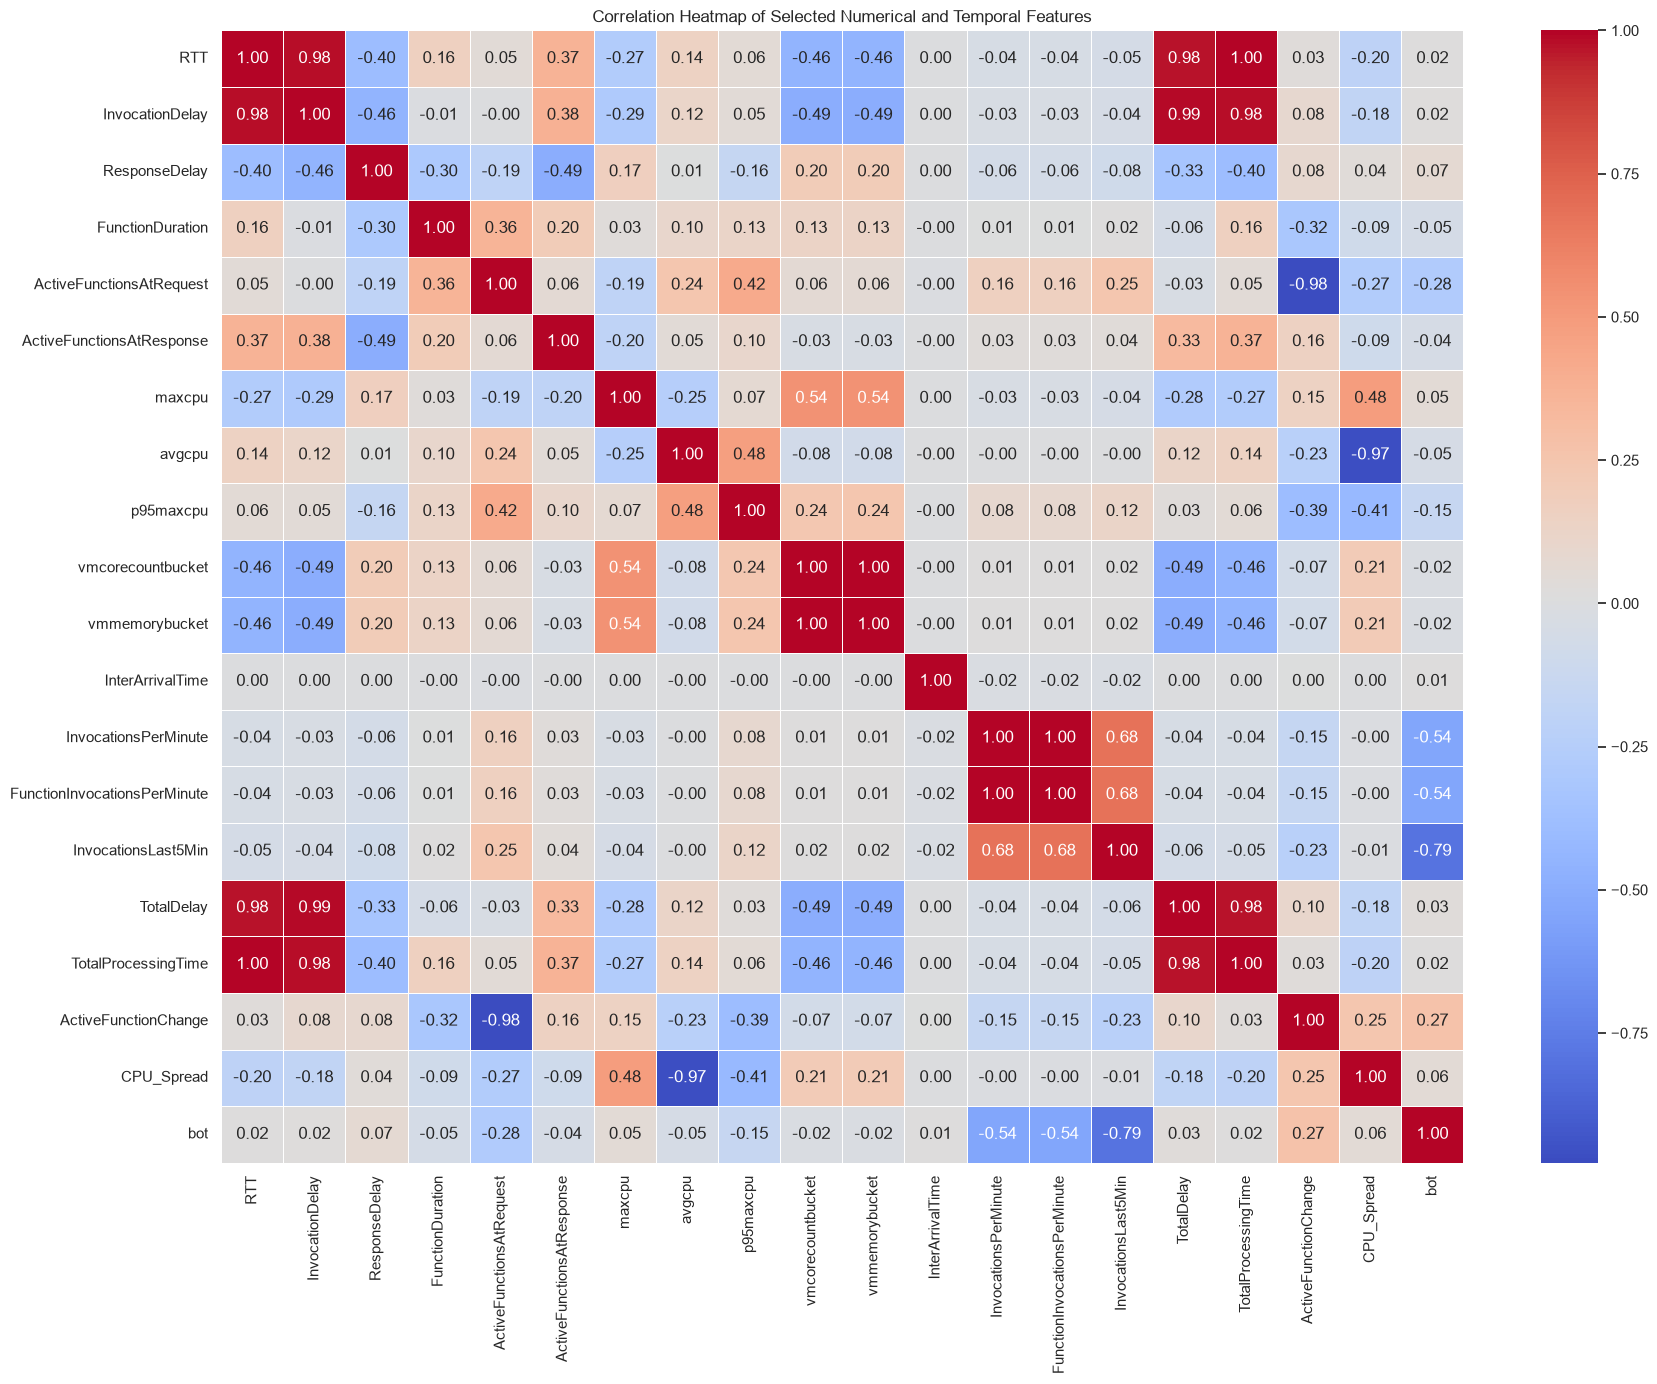

In [41]:

correlation_features = [
    "RTT",
    "InvocationDelay",
    "ResponseDelay",
    "FunctionDuration",
    "ActiveFunctionsAtRequest",
    "ActiveFunctionsAtResponse",
    "maxcpu",
    "avgcpu",
    "p95maxcpu",
    "vmcorecountbucket",
    "vmmemorybucket",
    "InterArrivalTime",
    "InvocationsPerMinute",
    "FunctionInvocationsPerMinute",
    "InvocationsLast5Min",
    "TotalDelay",
    "TotalProcessingTime",
    "ActiveFunctionChange",
    "CPU_Spread",
    "bot"
]

corr_df = work_df[
    correlation_features
].copy()

corr_matrix = corr_df.corr(
    method="pearson"
)

plt.figure(figsize=(18, 14))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    square=False
)

plt.title(
    "Correlation Heatmap of Selected Numerical and Temporal Features"
)

plt.xticks(
    rotation=90
)

plt.yticks(
    rotation=0
)

plt.tight_layout()
plt.show()

In [42]:
from sklearn.metrics import roc_auc_score

print("=" * 60)
print("UNIVARIATE FEATURE PREDICTABILITY CHECK")
print("=" * 60)

results = []

for feature in correlation_features:

    if feature == "bot":
        continue

    values = work_df[feature].values
    target = work_df["bot"].values

    try:
        auc_value = roc_auc_score(
            target,
            values
        )

        # Direction does not matter for leakage/separability.
        effective_auc = max(
            auc_value,
            1 - auc_value
        )

        results.append({
            "Feature": feature,
            "Univariate_AUC": effective_auc
        })

    except Exception:
        pass

univariate_auc_df = (
    pd.DataFrame(results)
    .sort_values(
        "Univariate_AUC",
        ascending=False
    )
)

univariate_auc_df

UNIVARIATE FEATURE PREDICTABILITY CHECK


,Feature,Univariate_AUC
14,InvocationsLast5Min,0.933191
12,InvocationsPerMinute,0.782521
13,FunctionInvocationsPerMinute,0.782521
11,InterArrivalTime,0.765644
4,ActiveFunctionsAtRequest,0.668163
17,ActiveFunctionChange,0.665610
3,FunctionDuration,0.546097
2,ResponseDelay,0.543548
18,CPU_Spread,0.536477
6,maxcpu,0.532638


In [43]:
categorical_audit_features = [
    "FunctionId",
    "functionTrigger",
    "vmcategory"
]

for feature in categorical_audit_features:

    print("\n" + "=" * 70)
    print(feature)
    print("=" * 70)

    audit_table = pd.crosstab(
        work_df[feature],
        work_df["bot"],
        normalize="index"
    ).round(4)

    display(audit_table)


FunctionId


bot,0,1
FunctionId,,
2,0.0092,0.9908
3,0.0092,0.9908
4,0.0092,0.9908
5,0.0092,0.9908
6,0.0092,0.9908
7,0.0092,0.9908
8,0.0092,0.9908
9,0.0092,0.9908
10,0.0092,0.9908



functionTrigger


bot,0,1
functionTrigger,,
http,0.3721,0.6279
notification,0.2999,0.7001
sql,0.2751,0.7249
storage,0.2446,0.7554
stream,0.3183,0.6817



vmcategory


bot,0,1
vmcategory,,
Delay-insensitive,0.2469,0.7531
Interactive,0.3296,0.6704
Unkown,0.3372,0.6628


Check Missing Values After Engineering

In [44]:
engineered_missing = (
    work_df[engineered_features]
    .isnull()
    .sum()
)

engineered_missing

InterArrivalTime                0
InvocationsPerMinute            0
FunctionInvocationsPerMinute    0
InvocationsLast5Min             0
TotalDelay                      0
TotalProcessingTime             0
ActiveFunctionChange            0
CPU_Spread                      0
dtype: int64

Infinite Value Check

In [45]:
numeric_work = work_df.select_dtypes(
    include=np.number
)

inf_counts = pd.Series({
    col: np.isinf(numeric_work[col]).sum()
    for col in numeric_work.columns
})

inf_counts[inf_counts > 0]

Series([], dtype: int64)

Save Interim Chronological Dataset

In [46]:
interim_path = (
    INTERIM_DIR
    / "dow_chronological_with_temporal_features.csv"
)

work_df.to_csv(
    interim_path,
    index=False
)

print("Saved:", interim_path)
print("Shape:", work_df.shape)

Saved: data\interim\dow_chronological_with_temporal_features.csv
Shape: (187087, 34)


## FEATURE SELECTION

Define Target and Features

In [47]:
TARGET = "bot"

numeric_features = [
    "SubmitTime",
    "RTT",
    "InvocationDelay",
    "ResponseDelay",
    "FunctionDuration",
    "ActiveFunctionsAtRequest",
    "ActiveFunctionsAtResponse",
    "maxcpu",
    "avgcpu",
    "p95maxcpu",
    "vmcorecountbucket",
    "vmmemorybucket",

    "InterArrivalTime",
    "InvocationsPerMinute",
    "FunctionInvocationsPerMinute",
    "InvocationsLast5Min",
    "TotalDelay",
    "TotalProcessingTime",
    "ActiveFunctionChange",
    "CPU_Spread"
]


categorical_features = [
    #"FunctionId",
    "functionTrigger",
    "vmcategory"
]

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numeric features: 20
Categorical features: 2


Final Feature Definition

In [48]:
TARGET = "bot"

numeric_features = [
    "RTT",
    "InvocationDelay",
    "ResponseDelay",
    "FunctionDuration",
    "ActiveFunctionsAtRequest",
    "ActiveFunctionsAtResponse",
    "maxcpu",
    "avgcpu",
    "p95maxcpu",
    "vmcorecountbucket",
    "vmmemorybucket",

    # Leakage-safe temporal workload features
    "InterArrivalTime",
    "FunctionInvocationsPerMinute",
    "InvocationsLast5Min",
    "TotalDelay",
    "TotalProcessingTime",
    "ActiveFunctionChange",
    "CPU_Spread"
]

categorical_features = [
    #"FunctionId",
    "functionTrigger",
    "vmcategory"
]

selected_features = (
    numeric_features
    + categorical_features
)

print(
    "Total selected raw features:",
    len(selected_features)
)

print("\nNumeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Total selected raw features: 20

Numeric features:
['RTT', 'InvocationDelay', 'ResponseDelay', 'FunctionDuration', 'ActiveFunctionsAtRequest', 'ActiveFunctionsAtResponse', 'maxcpu', 'avgcpu', 'p95maxcpu', 'vmcorecountbucket', 'vmmemorybucket', 'InterArrivalTime', 'FunctionInvocationsPerMinute', 'InvocationsLast5Min', 'TotalDelay', 'TotalProcessingTime', 'ActiveFunctionChange', 'CPU_Spread']

Categorical features:
['functionTrigger', 'vmcategory']


## CHRONOLOGICAL SPLITTING

# Revised Chronological Split Strategy

Inspection of the dataset showed that Normal and DoW observations occur in separate chronological blocks.

A simple global chronological 70/15/15 split therefore caused the validation and test sets to contain only DoW samples.

To preserve temporal ordering while ensuring that all three dataset splits contain both classes, a class-wise chronological split is used.

For each class independently:

- Earliest 70% → Training
- Following 15% → Validation
- Latest 15% → Test

No random shuffling is performed before partitioning.

Temporal ordering is preserved separately within the Normal and DoW workload streams.

Inspect Original Class Chronology

In [49]:
class_time_summary = (
    work_df
    .groupby(TARGET)["timestamp"]
    .agg(["min", "max", "count"])
)

class_time_summary

,min,max,count
bot,,,
0,2022-01-01 01:00:08.316000+00:00,2022-01-01 04:00:03.894000+00:00,56015
1,2022-01-02 03:00:32.422000+00:00,2022-01-02 17:59:37.586000+00:00,131072


In [50]:

# ============================================================
# SESSION AND CHRONOLOGICAL DATASET DIAGNOSTIC
# ============================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("DATASET SESSION AND TEMPORAL STRUCTURE AUDIT")
print("=" * 70)

print("\nDataset shape:", work_df.shape)

print("\nAvailable columns:")
print(work_df.columns.tolist())

print("\nClass distribution:")
print(work_df[TARGET].value_counts().sort_index())

print("\nClass-wise timestamp ranges:")
display(
    work_df.groupby(TARGET)["timestamp"]
    .agg(["min", "max", "count"])
)

# ------------------------------------------------------------
# Check function identifiers
# ------------------------------------------------------------

print("\nFUNCTION ID ANALYSIS")

if "FunctionId" in work_df.columns:

    function_summary = (
        work_df.groupby("FunctionId")
        .agg(
            Records=("Id", "size"),
            Start=("timestamp", "min"),
            End=("timestamp", "max"),
            Classes=(TARGET, "nunique"),
            Normal=(TARGET, lambda x: (x == 0).sum()),
            DoW=(TARGET, lambda x: (x == 1).sum())
        )
        .reset_index()
    )

    print(
        "Unique functions:",
        work_df["FunctionId"].nunique()
    )

    print(
        "Functions containing both classes:",
        (function_summary["Classes"] == 2).sum()
    )

    display(function_summary.head(20))

    function_summary.to_csv(
        RESULTS_DIR / "function_group_audit.csv",
        index=False
    )

# ------------------------------------------------------------
# Check IP identifiers
# ------------------------------------------------------------

print("\nIP GROUP ANALYSIS")

if "IP" in work_df.columns:

    ip_summary = (
        work_df.groupby("IP")
        .agg(
            Records=("Id", "size"),
            Start=("timestamp", "min"),
            End=("timestamp", "max"),
            Classes=(TARGET, "nunique")
        )
        .reset_index()
    )

    print("Unique IPs:", work_df["IP"].nunique())

    print(
        "IPs containing both classes:",
        (ip_summary["Classes"] == 2).sum()
    )

    display(ip_summary.head(20))

# ------------------------------------------------------------
# Inspect class distribution over calendar periods
# ------------------------------------------------------------

print("\nCLASS DISTRIBUTION BY DATE")

date_class_summary = pd.crosstab(
    work_df["timestamp"].dt.date,
    work_df[TARGET]
)

display(date_class_summary)

print("\nDiagnostic completed.")
print(
    "NOTE: FunctionId and IP are candidate grouping "
    "variables only. Neither is automatically an "
    "independent recording-session identifier."
)


DATASET SESSION AND TEMPORAL STRUCTURE AUDIT

Dataset shape: (187087, 34)

Available columns:
['Id', 'IP', 'bot', 'FunctionId', 'functionTrigger', 'timestamp', 'SubmitTime', 'RTT', 'InvocationDelay', 'ResponseDelay', 'FunctionDuration', 'ActiveFunctionsAtRequest', 'ActiveFunctionsAtResponse', 'maxcpu', 'avgcpu', 'p95maxcpu', 'vmcategory', 'vmcorecountbucket', 'vmmemorybucket', 'timestamp_original', 'hour', 'minute', 'second', 'day_of_week', 'elapsed_seconds', 'InterArrivalTime', 'time_minute', 'InvocationsPerMinute', 'FunctionInvocationsPerMinute', 'InvocationsLast5Min', 'TotalDelay', 'TotalProcessingTime', 'ActiveFunctionChange', 'CPU_Spread']

Class distribution:
bot
0     56015
1    131072
Name: count, dtype: int64

Class-wise timestamp ranges:


,min,max,count
bot,,,
0,2022-01-01 01:00:08.316000+00:00,2022-01-01 04:00:03.894000+00:00,56015
1,2022-01-02 03:00:32.422000+00:00,2022-01-02 17:59:37.586000+00:00,131072



FUNCTION ID ANALYSIS
Unique functions: 45
Functions containing both classes: 45


,FunctionId,Records,Start,End,Classes,Normal,DoW
0,2,2927,2022-01-01 02:00:11.228000+00:00,2022-01-02 17:58:47.371000+00:00,2,27,2900
1,3,2929,2022-01-01 02:00:11.564000+00:00,2022-01-02 17:58:48.189000+00:00,2,27,2902
2,4,2930,2022-01-01 02:00:12.682000+00:00,2022-01-02 17:58:48.749000+00:00,2,27,2903
3,5,2930,2022-01-01 02:00:13.177000+00:00,2022-01-02 17:58:49.035000+00:00,2,27,2903
4,6,2929,2022-01-01 02:00:13.704000+00:00,2022-01-02 17:58:49.402000+00:00,2,27,2902
5,7,2929,2022-01-01 02:00:14.206000+00:00,2022-01-02 17:58:49.938000+00:00,2,27,2902
6,8,2929,2022-01-01 02:00:14.987000+00:00,2022-01-02 17:58:51.097000+00:00,2,27,2902
7,9,2929,2022-01-01 02:00:15.952000+00:00,2022-01-02 17:58:51.545000+00:00,2,27,2902
8,10,2929,2022-01-01 02:00:17.048000+00:00,2022-01-02 17:58:52.583000+00:00,2,27,2902
9,12,3514,2022-01-01 02:00:02.416000+00:00,2022-01-02 17:59:19.108000+00:00,2,579,2935



IP GROUP ANALYSIS
Unique IPs: 7587
IPs containing both classes: 0


,IP,Records,Start,End,Classes
0,0.10.141.169,8,2022-01-01 01:49:50.224000+00:00,2022-01-01 01:49:56.008000+00:00,1
1,0.10.180.85,9,2022-01-01 02:17:54.704000+00:00,2022-01-01 02:17:59.995000+00:00,1
2,0.11.220.224,1709,2022-01-02 03:27:58.026000+00:00,2022-01-02 17:49:06.903000+00:00,1
3,0.117.62.10,9,2022-01-01 03:39:52.828000+00:00,2022-01-01 03:39:58.754000+00:00,1
4,0.119.192.14,9,2022-01-01 02:14:30.217000+00:00,2022-01-01 02:14:36.028000+00:00,1
5,0.146.196.120,4,2022-01-01 03:50:14.760000+00:00,2022-01-01 03:50:16.662000+00:00,1
6,0.146.38.129,9,2022-01-01 02:03:31.900000+00:00,2022-01-01 02:03:35.880000+00:00,1
7,0.15.58.247,9,2022-01-01 02:40:35.260000+00:00,2022-01-01 02:40:40.680000+00:00,1
8,0.152.187.176,9,2022-01-01 02:40:41.359000+00:00,2022-01-01 02:40:46.935000+00:00,1
9,0.175.234.232,9,2022-01-01 02:37:32.749000+00:00,2022-01-01 02:37:39.088000+00:00,1



CLASS DISTRIBUTION BY DATE


bot,0,1
timestamp,,
2022-01-01,56015,0
2022-01-02,0,131072



Diagnostic completed.
NOTE: FunctionId and IP are candidate grouping variables only. Neither is automatically an independent recording-session identifier.


FUNCTION-LEVEL TEMPORAL SEQUENCE FEASIBILITY

In [51]:

# ============================================================
# FUNCTION-LEVEL BINARY CLASSIFICATION FEASIBILITY TEST
# ============================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("FUNCTION-LEVEL TEMPORAL SEQUENCE FEASIBILITY")
print("=" * 70)

SEQ_LEN = 30

function_class_counts = pd.crosstab(
    work_df["FunctionId"],
    work_df[TARGET]
).reindex(columns=[0, 1], fill_value=0)

function_class_counts.columns = [
    "Normal_Count",
    "DoW_Count"
]

function_class_counts["Total"] = (
    function_class_counts["Normal_Count"]
    + function_class_counts["DoW_Count"]
)

function_class_counts["Has_Both_Classes"] = (
    (function_class_counts["Normal_Count"] > 0)
    & (function_class_counts["DoW_Count"] > 0)
)

function_class_counts["Normal_Window_Possible"] = (
    function_class_counts["Normal_Count"] >= SEQ_LEN
)

function_class_counts["DoW_Window_Possible"] = (
    function_class_counts["DoW_Count"] >= SEQ_LEN
)

function_class_counts["Both_Class_Window_Possible"] = (
    function_class_counts["Normal_Window_Possible"]
    & function_class_counts["DoW_Window_Possible"]
)

display(function_class_counts)

print("\nSUMMARY")

print(
    "Total functions:",
    len(function_class_counts)
)

print(
    "Functions containing both classes:",
    function_class_counts["Has_Both_Classes"].sum()
)

print(
    "Functions with at least 30 records per class:",
    function_class_counts[
        "Both_Class_Window_Possible"
    ].sum()
)

print(
    "\nNormal observations per function:"
)

print(
    function_class_counts["Normal_Count"].describe()
)

print(
    "\nDoW observations per function:"
)

print(
    function_class_counts["DoW_Count"].describe()
)

print("\nChecking within-function chronology...")

for function_id, group in work_df.groupby("FunctionId"):

    group = group.sort_values("timestamp")

    assert group["timestamp"].is_monotonic_increasing

print("Within-function chronological ordering: PASSED")

print("\nDiagnostic completed.")


FUNCTION-LEVEL TEMPORAL SEQUENCE FEASIBILITY


,Normal_Count,DoW_Count,Total,Has_Both_Classes,Normal_Window_Possible,DoW_Window_Possible,Both_Class_Window_Possible
FunctionId,,,,,,,
2,27,2900,2927,True,False,True,False
3,27,2902,2929,True,False,True,False
4,27,2903,2930,True,False,True,False
5,27,2903,2930,True,False,True,False
6,27,2902,2929,True,False,True,False
7,27,2902,2929,True,False,True,False
8,27,2902,2929,True,False,True,False
9,27,2902,2929,True,False,True,False
10,27,2902,2929,True,False,True,False



SUMMARY
Total functions: 45
Functions containing both classes: 45
Functions with at least 30 records per class: 36

Normal observations per function:
count      45.000000
mean     1244.777778
std       861.697529
min        27.000000
25%       596.000000
50%      1393.000000
75%      1791.000000
max      2563.000000
Name: Normal_Count, dtype: float64

DoW observations per function:
count      45.000000
mean     2912.711111
std        39.453438
min      2855.000000
25%      2890.000000
50%      2902.000000
75%      2940.000000
max      2973.000000
Name: DoW_Count, dtype: float64

Checking within-function chronology...
Within-function chronological ordering: PASSED

Diagnostic completed.


Define Class-Wise Chronological Split Function

In [52]:

# ============================================================
# GROUP-DISJOINT DATASET SPLITTING
# Only valid for verified independent recording sessions
# ============================================================

from sklearn.model_selection import GroupShuffleSplit

# IMPORTANT:
# Set this ONLY after identifying a real session identifier.
# Do not replace with TARGET, bot, or artificial class IDs.

# Group identifier for cross-function binary classification
SESSION_COL = "FunctionId"

def session_disjoint_split(
    data,
    session_col,
    target_col="bot",
    test_size=0.15,
    val_size=0.15,
    random_state=42
):
    if session_col is None:
        raise ValueError(
            "No verified session identifier is available. "
            "Check the session audit and original dataset "
            "documentation before proceeding."
        )

    if session_col not in data.columns:
        raise ValueError(
            f"Session column {session_col} does not exist."
        )

    if session_col == target_col:
        raise ValueError(
            "Target labels cannot be used as session IDs."
        )

    if data[session_col].isna().any():
        raise ValueError(
            "Missing session identifiers were detected."
        )

    ordered = (
        data.sort_values(["timestamp", "Id"])
        .copy()
    )

    if ordered[session_col].nunique() < 3:
        raise ValueError(
            "At least three independent groups are needed."
        )

    # Hold out complete groups for final testing.
    outer_split = GroupShuffleSplit(
        n_splits=100,
        test_size=test_size,
        random_state=random_state
    )

    for train_val_idx, test_idx in outer_split.split(
        ordered,
        ordered[target_col],
        groups=ordered[session_col]
    ):

        train_val = ordered.iloc[train_val_idx].copy()
        test = ordered.iloc[test_idx].copy()

        relative_val_size = val_size / (1 - test_size)

        inner_split = GroupShuffleSplit(
            n_splits=100,
            test_size=relative_val_size,
            random_state=random_state
        )

        for train_idx, val_idx in inner_split.split(
            train_val,
            train_val[target_col],
            groups=train_val[session_col]
        ):

            train = train_val.iloc[train_idx].copy()
            val = train_val.iloc[val_idx].copy()

            partitions = [train, val, test]

            if all(
                set(part[target_col].unique()) == {0, 1}
                for part in partitions
            ):

                return tuple(
                    part.sort_values(
                        ["timestamp", "Id"]
                    ).copy()
                    for part in partitions
                )

    raise ValueError(
        "Could not create three group-disjoint "
        "partitions containing both classes. "
        "Additional independent sessions may be needed."
    )


Create Revised Class-Wise Splits

In [53]:

# ============================================================
# CREATE GROUP-DISJOINT TRAIN / VALIDATION / TEST SETS
# ============================================================

if SESSION_COL is None:
    raise ValueError(
        "STOP: A verified independent session column "
        "has not yet been identified. "
        "Do not substitute FunctionId or IP without "
        "validating that it represents genuine "
        "independent recording units."
    )

train_df, val_df, test_df = session_disjoint_split(
    data=work_df,
    session_col=SESSION_COL,
    target_col=TARGET,
    test_size=0.15,
    val_size=0.15,
    random_state=42
)

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Testing shape:", test_df.shape)

print("\nClass distribution:")

for name, part in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(
        f"\n{name}:",
        part[TARGET].value_counts().to_dict()
    )

    print(
    "Number of held-out function groups:",
    part[SESSION_COL].nunique()
)


Training shape: (126382, 34)
Validation shape: (29533, 34)
Testing shape: (31172, 34)

Class distribution:

Training: {1: 90166, 0: 36216}
Number of held-out function groups: 31

Validation: {1: 20469, 0: 9064}
Number of held-out function groups: 7

Testing: {1: 20437, 0: 10735}
Number of held-out function groups: 7


Verify Both Classes Exist in Each Split

In [54]:

# ============================================================
# BINARY CLASS AND GROUP SEPARATION VERIFICATION
# ============================================================

partitions = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

split_report = []

for name, part in partitions.items():

    class_counts = part[TARGET].value_counts()

    split_report.append({
        "Split": name,
        "Records": len(part),
        "Function_Groups": part[SESSION_COL].nunique(),
        "Normal": int(class_counts.get(0, 0)),
        "DoW": int(class_counts.get(1, 0)),
        "Start": part["timestamp"].min(),
        "End": part["timestamp"].max()
    })

    assert set(part[TARGET].unique()) == {0, 1}, (
        f"{name} does not contain both classes."
    )

split_report = pd.DataFrame(split_report)

display(split_report)

train_groups = set(train_df[SESSION_COL])
val_groups = set(val_df[SESSION_COL])
test_groups = set(test_df[SESSION_COL])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

print("Both classes in each split: PASSED")
print("Group separation: PASSED")

split_report.to_csv(
    RESULTS_DIR / "group_split_report.csv",
    index=False
)


,Split,Records,Function_Groups,Normal,DoW,Start,End
0,Train,126382,31,36216,90166,2022-01-01 01:00:08.316000+00:00,2022-01-02 17:59:36.180000+00:00
1,Validation,29533,7,9064,20469,2022-01-01 01:00:09.984000+00:00,2022-01-02 17:59:29.732000+00:00
2,Test,31172,7,10735,20437,2022-01-01 01:00:12.007000+00:00,2022-01-02 17:59:37.586000+00:00


Both classes in each split: PASSED
Group separation: PASSED


Verify Chronology Within Each Class

In [55]:

# ============================================================
# SESSION AND CHRONOLOGICAL INTEGRITY VERIFICATION
# ============================================================

for name, part in partitions.items():

    assert part["timestamp"].is_monotonic_increasing, (
        f"{name} is not sorted chronologically."
    )

    assert not part["Id"].duplicated().any(), (
        f"{name} contains duplicate record IDs."
    )

    for session_id, session_df in part.groupby(SESSION_COL):

        assert session_df["timestamp"].is_monotonic_increasing, (
            f"Session {session_id} is not chronologically ordered."
        )

print("Within-session chronology: PASSED")

train_ids = set(train_df["Id"])
val_ids = set(val_df["Id"])
test_ids = set(test_df["Id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("Record separation: PASSED")

GLOBAL_CHRONOLOGY = (
    train_df["timestamp"].max() < val_df["timestamp"].min()
    and
    val_df["timestamp"].max() < test_df["timestamp"].min()
)

print("Global chronological separation:", GLOBAL_CHRONOLOGY)

if not GLOBAL_CHRONOLOGY:
    print(
        "NOTE: This is a group-disjoint held-out-session "
        "classification experiment, NOT a strict "
        "future-time chronological evaluation."
    )


Within-session chronology: PASSED
Record separation: PASSED
Global chronological separation: False
NOTE: This is a group-disjoint held-out-session classification experiment, NOT a strict future-time chronological evaluation.


Save Raw Chronological Splits

In [56]:
train_df.to_csv(
    PROCESSED_DIR / "train_chronological.csv",
    index=False
)

val_df.to_csv(
    PROCESSED_DIR / "validation_chronological.csv",
    index=False
)

test_df.to_csv(
    PROCESSED_DIR / "test_chronological.csv",
    index=False
)

print("Chronological CSV splits saved.")

Chronological CSV splits saved.


## PREPROCESSOR

Prepare X and y

In [57]:
X_train_raw = train_df[selected_features].copy()
X_val_raw = val_df[selected_features].copy()
X_test_raw = test_df[selected_features].copy()

y_train_raw = train_df[TARGET].to_numpy()
y_val_raw = val_df[TARGET].to_numpy()
y_test_raw = test_df[TARGET].to_numpy()

print("X_train:", X_train_raw.shape)
print("X_val  :", X_val_raw.shape)
print("X_test :", X_test_raw.shape)

X_train: (126382, 20)
X_val  : (29533, 20)
X_test : (31172, 20)


Define Preprocessing Pipeline

In [58]:
preprocessor = ColumnTransformer(
    transformers=[

        (
            "numeric",
            StandardScaler(),
            numeric_features
        ),

        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print(preprocessor)

ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                 ['RTT', 'InvocationDelay', 'ResponseDelay',
                                  'FunctionDuration',
                                  'ActiveFunctionsAtRequest',
                                  'ActiveFunctionsAtResponse', 'maxcpu',
                                  'avgcpu', 'p95maxcpu', 'vmcorecountbucket',
                                  'vmmemorybucket', 'InterArrivalTime',
                                  'FunctionInvocationsPerMinute',
                                  'InvocationsLast5Min', 'TotalDelay',
                                  'TotalProcessingTime', 'ActiveFunctionChange',
                                  'CPU_Spread']),
                                ('categorical',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['functionTrigger', 'vmcategory'

Fit Only Training Data

In [59]:
X_train_processed = (
    preprocessor.fit_transform(X_train_raw)
)

X_val_processed = (
    preprocessor.transform(X_val_raw)
)

X_test_processed = (
    preprocessor.transform(X_test_raw)
)

print(
    "Train processed:",
    X_train_processed.shape
)

print(
    "Validation processed:",
    X_val_processed.shape
)

print(
    "Test processed:",
    X_test_processed.shape
)

Train processed: (126382, 26)
Validation processed: (29533, 26)
Test processed: (31172, 26)


Get Final Feature Names

In [60]:
final_feature_names = (
    preprocessor.get_feature_names_out()
)

print(
    "Number of final encoded features:",
    len(final_feature_names)
)

print(final_feature_names)

Number of final encoded features: 26
['numeric__RTT' 'numeric__InvocationDelay' 'numeric__ResponseDelay'
 'numeric__FunctionDuration' 'numeric__ActiveFunctionsAtRequest'
 'numeric__ActiveFunctionsAtResponse' 'numeric__maxcpu' 'numeric__avgcpu'
 'numeric__p95maxcpu' 'numeric__vmcorecountbucket'
 'numeric__vmmemorybucket' 'numeric__InterArrivalTime'
 'numeric__FunctionInvocationsPerMinute' 'numeric__InvocationsLast5Min'
 'numeric__TotalDelay' 'numeric__TotalProcessingTime'
 'numeric__ActiveFunctionChange' 'numeric__CPU_Spread'
 'categorical__functionTrigger_http'
 'categorical__functionTrigger_notification'
 'categorical__functionTrigger_sql' 'categorical__functionTrigger_storage'
 'categorical__functionTrigger_stream'
 'categorical__vmcategory_Delay-insensitive'
 'categorical__vmcategory_Interactive' 'categorical__vmcategory_Unkown']


Save Preprocessor

In [61]:
preprocessor_path = (
    MODELS_DIR
    / "preprocessor.joblib"
)

joblib.dump(
    preprocessor,
    preprocessor_path
)

print(
    "Preprocessor saved to:",
    preprocessor_path
)

Preprocessor saved to: models\preprocessor.joblib


## TEMPORAL SEQUENCE CONSTRUCTION

Define Sequence Length

In [62]:
SEQUENCE_LENGTH = 30

print(
    "Sequence length:",
    SEQUENCE_LENGTH
)

Sequence length: 30


Class-Wise Temporal Sequence Creation Function

In [63]:
def create_temporal_sequences(
    X,
    y,
    sequence_length=30
):
    """
    Create sequences from observations in their existing order.

    IMPORTANT:
    Sequence formation does not use the target label
    to group or partition samples.

    The target is the label of the final observation
    in each temporal window.
    """

    X_sequences = []
    y_sequences = []

    for end_index in range(
        sequence_length - 1,
        len(X)
    ):

        start_index = (
            end_index
            - sequence_length
            + 1
        )

        X_sequences.append(
            X[
                start_index:
                end_index + 1
            ]
        )

        y_sequences.append(
            y[end_index]
        )

    return (
        np.asarray(
            X_sequences,
            dtype=np.float32
        ),
        np.asarray(
            y_sequences,
            dtype=np.int32
        )
    )

Create Sequences by Stream

In [64]:

# ============================================================
# FUNCTION-SAFE TEMPORAL SEQUENCE CONSTRUCTION
# Prevent windows crossing long recording gaps
# ============================================================

import numpy as np
import pandas as pd

def create_sequences_by_session(
    X,
    y,
    session_ids,
    timestamps,
    sequence_length=30,
    max_gap="1h"
):
    """
    Create chronological temporal sequences within FunctionId.

    Rules:
    1. Never combine different FunctionIds.
    2. Never cross large recording gaps.
    3. Never group records using target labels.
    4. Assign each window the label of its last record.
    """

    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.int32).reshape(-1)

    session_ids = np.asarray(session_ids)
    timestamps = pd.Series(
        pd.to_datetime(timestamps)
    ).reset_index(drop=True)

    if not (
        len(X) == len(y)
        == len(session_ids)
        == len(timestamps)
    ):
        raise ValueError(
            "X, y, session_ids and timestamps "
            "must have identical lengths."
        )

    gap_threshold = pd.Timedelta(max_gap)

    X_sequences = []
    y_sequences = []

    skipped_short_segments = 0
    detected_gaps = 0

    # Group only by genuine FunctionId
    for function_id in pd.unique(session_ids):

        idx = np.flatnonzero(
            session_ids == function_id
        )

        # Chronological order within function
        idx = idx[np.argsort(
            timestamps.iloc[idx].to_numpy(),
            kind="stable"
        )]

        function_times = timestamps.iloc[idx]

        # Identify large time gaps
        time_differences = function_times.diff()

        new_segment = (
            time_differences > gap_threshold
        ).fillna(False).to_numpy()

        detected_gaps += int(new_segment.sum())

        segment_ids = np.cumsum(new_segment)

        # Create windows within continuous segments
        for segment in np.unique(segment_ids):

            segment_idx = idx[
                segment_ids == segment
            ]

            if len(segment_idx) < sequence_length:
                skipped_short_segments += 1
                continue

            for end_pos in range(
                sequence_length - 1,
                len(segment_idx)
            ):

                window_idx = segment_idx[
                    end_pos - sequence_length + 1:
                    end_pos + 1
                ]

                window = X[window_idx]
                label = y[window_idx[-1]]

                X_sequences.append(window)
                y_sequences.append(label)

    if not X_sequences:
        raise ValueError(
            "No valid temporal windows created."
        )

    X_sequences = np.stack(
        X_sequences
    ).astype(np.float32)

    y_sequences = np.asarray(
        y_sequences,
        dtype=np.int32
    )

    print("Detected recording gaps:", detected_gaps)
    print(
        "Short segments skipped:",
        skipped_short_segments
    )
    print("Sequences created:", len(X_sequences))

    return X_sequences, y_sequences


Create Training Sequences

In [65]:

X_train_seq, y_train_seq = create_sequences_by_session(
    X=X_train_processed,
    y=y_train_raw,
    session_ids=train_df[SESSION_COL],
    timestamps=train_df["timestamp"],
    sequence_length=SEQUENCE_LENGTH
)

print("Training:", X_train_seq.shape)
print(pd.Series(y_train_seq).value_counts().sort_index())


Detected recording gaps: 31
Short segments skipped: 6
Sequences created: 124596
Training: (124596, 30, 26)
0    35329
1    89267
Name: count, dtype: int64


Create Validation Sequences

In [66]:

X_val_seq, y_val_seq = create_sequences_by_session(
    X=X_val_processed,
    y=y_val_raw,
    session_ids=val_df[SESSION_COL],
    timestamps=val_df["timestamp"],
    sequence_length=SEQUENCE_LENGTH
)

print("Validation:", X_val_seq.shape)
print(pd.Series(y_val_seq).value_counts().sort_index())


Detected recording gaps: 7
Short segments skipped: 2
Sequences created: 29131
Validation: (29131, 30, 26)
0     8865
1    20266
Name: count, dtype: int64


Create Test Sequences

In [67]:

X_test_seq, y_test_seq = create_sequences_by_session(
    X=X_test_processed,
    y=y_test_raw,
    session_ids=test_df[SESSION_COL],
    timestamps=test_df["timestamp"],
    sequence_length=SEQUENCE_LENGTH
)

print("Testing:", X_test_seq.shape)
print(pd.Series(y_test_seq).value_counts().sort_index())


Detected recording gaps: 7
Short segments skipped: 1
Sequences created: 30768
Testing: (30768, 30, 26)
0    10534
1    20234
Name: count, dtype: int64


Final Class Distribution Check

In [68]:
print(
    "TRAIN:",
    np.unique(
        y_train_seq,
        return_counts=True
    )
)

print(
    "VALIDATION:",
    np.unique(
        y_val_seq,
        return_counts=True
    )
)

print(
    "TEST:",
    np.unique(
        y_test_seq,
        return_counts=True
    )
)

TRAIN: (array([0, 1], dtype=int32), array([35329, 89267]))
VALIDATION: (array([0, 1], dtype=int32), array([ 8865, 20266]))
TEST: (array([0, 1], dtype=int32), array([10534, 20234]))


Verify Tensor Shape

In [69]:
print(
    "Training tensor shape:",
    X_train_seq.shape
)

print(
    "\nInterpretation:"
)

print(
    "Samples   :",
    X_train_seq.shape[0]
)

print(
    "Time steps:",
    X_train_seq.shape[1]
)

print(
    "Features  :",
    X_train_seq.shape[2]
)

Training tensor shape: (124596, 30, 26)

Interpretation:
Samples   : 124596
Time steps: 30
Features  : 26


Sequence Integrity Check

In [70]:
assert X_train_seq.shape[1] == SEQUENCE_LENGTH
assert X_val_seq.shape[1] == SEQUENCE_LENGTH
assert X_test_seq.shape[1] == SEQUENCE_LENGTH

assert X_train_seq.shape[0] == len(y_train_seq)
assert X_val_seq.shape[0] == len(y_val_seq)
assert X_test_seq.shape[0] == len(y_test_seq)

print(
    "Temporal sequence integrity check passed."
)

Temporal sequence integrity check passed.


Check NaN Values in Sequence Arrays

In [71]:
print(
    "NaN in X_train:",
    np.isnan(X_train_seq).sum()
)

print(
    "NaN in X_val:",
    np.isnan(X_val_seq).sum()
)

print(
    "NaN in X_test:",
    np.isnan(X_test_seq).sum()
)

NaN in X_train: 0
NaN in X_val: 0
NaN in X_test: 0


Check Infinite Values

In [72]:
print(
    "Infinite values in X_train:",
    np.isinf(X_train_seq).sum()
)

print(
    "Infinite values in X_val:",
    np.isinf(X_val_seq).sum()
)

print(
    "Infinite values in X_test:",
    np.isinf(X_test_seq).sum()
)

Infinite values in X_train: 0
Infinite values in X_val: 0
Infinite values in X_test: 0


Sequence Class Distribution

In [73]:
sequence_distribution = pd.DataFrame({
    "Dataset": [
        "Train",
        "Validation",
        "Test"
    ],

    "Normal": [
        np.sum(y_train_seq == 0),
        np.sum(y_val_seq == 0),
        np.sum(y_test_seq == 0)
    ],

    "DoW": [
        np.sum(y_train_seq == 1),
        np.sum(y_val_seq == 1),
        np.sum(y_test_seq == 1)
    ]
})

sequence_distribution

,Dataset,Normal,DoW
0,Train,35329,89267
1,Validation,8865,20266
2,Test,10534,20234


Leakage Audit

In [74]:

# Group-disjoint leakage checks
assert set(train_df[SESSION_COL]).isdisjoint(
    set(val_df[SESSION_COL])
)
assert set(train_df[SESSION_COL]).isdisjoint(
    set(test_df[SESSION_COL])
)
assert set(val_df[SESSION_COL]).isdisjoint(
    set(test_df[SESSION_COL])
)

print("No sessions shared between partitions: PASSED")

for name, labels in [
    ("Train", y_train_seq),
    ("Validation", y_val_seq),
    ("Test", y_test_seq)
]:
    assert set(np.unique(labels).tolist()) == {0, 1}, (
        f"{name} sequence labels lack both classes."
    )

print("Binary sequence-label validation: PASSED")


No sessions shared between partitions: PASSED
Binary sequence-label validation: PASSED


Save Sequence Arrays

In [75]:
SEQUENCE_DIR = (
    PROCESSED_DIR
    / "sequences"
)

SEQUENCE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

Save Temporal Sequences

In [76]:

# ============================================================
# SAVE TEMPORAL SEQUENCES - CORRECTED
# ============================================================

import numpy as np
from pathlib import Path

# Use the original notebook sequence directory
SAVE_DIR = Path(SEQUENCE_DIR).resolve()
SAVE_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("SAVING TEMPORAL SEQUENCE DATASETS")
print("=" * 65)

print("Save directory:", SAVE_DIR)

sequence_files = {
    "X_train.npy": X_train_seq,
    "y_train.npy": y_train_seq,
    "X_val.npy": X_val_seq,
    "y_val.npy": y_val_seq,
    "X_test.npy": X_test_seq,
    "y_test.npy": y_test_seq
}

# Save files
for filename, array in sequence_files.items():

    file_path = SAVE_DIR / filename

    np.save(file_path, array, allow_pickle=False)

    print(
        f"SAVED: {filename} | Shape: {array.shape}"
    )

# Verify files
print("\nVERIFYING SAVED FILES")

for filename, array in sequence_files.items():

    file_path = SAVE_DIR / filename

    assert file_path.exists(), (
        f"File missing: {file_path}"
    )

    saved_array = np.load(
        file_path,
        mmap_mode="r",
        allow_pickle=False
    )

    assert saved_array.shape == array.shape, (
        f"Shape mismatch: {filename}"
    )

    assert saved_array.dtype == array.dtype, (
        f"Data type mismatch: {filename}"
    )

    print(f"VERIFIED: {filename}")

print("\nALL SIX SEQUENCE FILES SAVED AND VERIFIED")


SAVING TEMPORAL SEQUENCE DATASETS
Save directory: C:\MATT PROJECT\DoW Serverless Project\data\processed\sequences
SAVED: X_train.npy | Shape: (124596, 30, 26)
SAVED: y_train.npy | Shape: (124596,)
SAVED: X_val.npy | Shape: (29131, 30, 26)
SAVED: y_val.npy | Shape: (29131,)
SAVED: X_test.npy | Shape: (30768, 30, 26)
SAVED: y_test.npy | Shape: (30768,)

VERIFYING SAVED FILES
VERIFIED: X_train.npy
VERIFIED: y_train.npy
VERIFIED: X_val.npy
VERIFIED: y_val.npy
VERIFIED: X_test.npy
VERIFIED: y_test.npy

ALL SIX SEQUENCE FILES SAVED AND VERIFIED


Save Metadata

In [77]:

# ============================================================
# SAVE METADATA - FUNCTION-DISJOINT BINARY CLASSIFICATION
# ============================================================

import json
import numpy as np

metadata = {
    "project": "Adaptive Temporal DoW Detection",

    "target": TARGET,

    "sequence_length": int(SEQUENCE_LENGTH),

    "numeric_features": list(numeric_features),

    "categorical_features": list(categorical_features),

    "final_encoded_feature_count": int(
        X_train_seq.shape[2]
    ),

    "final_feature_names": list(final_feature_names),

    "train_sequences": int(X_train_seq.shape[0]),

    "validation_sequences": int(X_val_seq.shape[0]),

    "test_sequences": int(X_test_seq.shape[0]),

    "train_classes": np.unique(
        y_train_seq
    ).astype(int).tolist(),

    "validation_classes": np.unique(
        y_val_seq
    ).astype(int).tolist(),

    "test_classes": np.unique(
        y_test_seq
    ).astype(int).tolist(),

    "class_mapping": {
        "0": "Normal",
        "1": "DoW"
    },

    "split_strategy": (
        "FunctionId-disjoint training, validation and testing; "
        "not globally chronological"
    ),

    "group_column": SESSION_COL,

    "globally_chronological": bool(GLOBAL_CHRONOLOGY),

    "sequence_strategy": (
        "Sliding temporal windows within each FunctionId; "
        "label assigned from final observation"
    ),

    "binary_evaluation_ready": bool(
        all(
            set(np.unique(labels).tolist()) == {0, 1}
            for labels in [
                y_train_seq,
                y_val_seq,
                y_test_seq
            ]
        )
    ),

    "train_start": str(train_df["timestamp"].min()),
    "train_end": str(train_df["timestamp"].max()),

    "validation_start": str(val_df["timestamp"].min()),
    "validation_end": str(val_df["timestamp"].max()),

    "test_start": str(test_df["timestamp"].min()),
    "test_end": str(test_df["timestamp"].max()),

    "train_function_groups": int(
        train_df[SESSION_COL].nunique()
    ),

    "validation_function_groups": int(
        val_df[SESSION_COL].nunique()
    ),

    "test_function_groups": int(
        test_df[SESSION_COL].nunique()
    )
}

# Save metadata as JSON
metadata_path = PROCESSED_DIR / "sequence_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

print("=" * 65)
print("METADATA SAVED SUCCESSFULLY")
print("=" * 65)

print("File location:", metadata_path)
print("Sequence length:", metadata["sequence_length"])
print("Encoded feature count:", metadata["final_encoded_feature_count"])

print("\nFunction groups:")
print("Training:", metadata["train_function_groups"])
print("Validation:", metadata["validation_function_groups"])
print("Testing:", metadata["test_function_groups"])

print("\nBinary evaluation ready:", metadata["binary_evaluation_ready"])
print("Globally chronological:", metadata["globally_chronological"])


METADATA SAVED SUCCESSFULLY
File location: data\processed\sequence_metadata.json
Sequence length: 30
Encoded feature count: 26

Function groups:
Training: 31
Validation: 7
Testing: 7

Binary evaluation ready: True
Globally chronological: False


In [78]:
metadata_path = (
    PROCESSED_DIR
    / "sequence_metadata.json"
)

with open(
    metadata_path,
    "w"
) as file:

    json.dump(
        metadata,
        file,
        indent=4
    )

print(
    "Metadata saved:",
    metadata_path
)

Metadata saved: data\processed\sequence_metadata.json


Save Final Feature Names

In [79]:
feature_names_path = (
    PROCESSED_DIR
    / "final_feature_names.csv"
)

pd.DataFrame({
    "Feature":
        final_feature_names
}).to_csv(
    feature_names_path,
    index=False
)

print(
    "Feature names saved:",
    feature_names_path
)

Feature names saved: data\processed\final_feature_names.csv


Final Notebook Validation

In [80]:

# ============================================================
# NOTEBOOK 01 - FINAL VALIDATION
# FunctionId-Disjoint Supervised Binary Classification
# ============================================================

import numpy as np
import pandas as pd
import json

print("=" * 70)
print("NOTEBOOK 01 - FINAL VALIDATION REPORT")
print("=" * 70)

# ------------------------------------------------------------
# 1. DATASET VERIFICATION
# ------------------------------------------------------------

print("\n1. DATASET VERIFICATION")

print("Original dataset shape:", df.shape)
print("Processed dataset shape:", work_df.shape)

print("\nOriginal class distribution:")
print(work_df[TARGET].value_counts().sort_index())

assert not work_df.empty, "Processed dataset is empty."

assert TARGET in work_df.columns, (
    "Target column is missing."
)

assert SESSION_COL in work_df.columns, (
    "Function grouping column is missing."
)

print("Dataset verification: PASSED")

# ------------------------------------------------------------
# 2. TRAIN / VALIDATION / TEST SPLIT VERIFICATION
# ------------------------------------------------------------

print("\n2. DATASET SPLIT VERIFICATION")

partitions = {
    "Training": train_df,
    "Validation": val_df,
    "Testing": test_df
}

for name, part in partitions.items():

    print(f"\n{name}")
    print("Shape:", part.shape)
    print("Function groups:", part[SESSION_COL].nunique())

    print(
        "Class distribution:",
        part[TARGET].value_counts().sort_index().to_dict()
    )

    assert not part.empty, f"{name} dataset is empty."

    assert set(part[TARGET].unique()) == {0, 1}, (
        f"{name} does not contain both classes."
    )

print("\nBinary class verification: PASSED")

# ------------------------------------------------------------
# 3. FUNCTION GROUP SEPARATION
# ------------------------------------------------------------

print("\n3. FUNCTION GROUP SEPARATION")

train_groups = set(train_df[SESSION_COL].unique())
val_groups = set(val_df[SESSION_COL].unique())
test_groups = set(test_df[SESSION_COL].unique())

assert train_groups.isdisjoint(val_groups), (
    "Training and validation function groups overlap."
)

assert train_groups.isdisjoint(test_groups), (
    "Training and testing function groups overlap."
)

assert val_groups.isdisjoint(test_groups), (
    "Validation and testing function groups overlap."
)

print("Training function groups:", len(train_groups))
print("Validation function groups:", len(val_groups))
print("Testing function groups:", len(test_groups))

print("FunctionId separation: PASSED")

# ------------------------------------------------------------
# 4. RECORD-LEVEL SEPARATION
# ------------------------------------------------------------

print("\n4. RECORD-LEVEL SEPARATION")

train_ids = set(train_df["Id"])
val_ids = set(val_df["Id"])
test_ids = set(test_df["Id"])

assert train_ids.isdisjoint(val_ids), (
    "Training and validation record IDs overlap."
)

assert train_ids.isdisjoint(test_ids), (
    "Training and testing record IDs overlap."
)

assert val_ids.isdisjoint(test_ids), (
    "Validation and testing record IDs overlap."
)

print("Record-level separation: PASSED")

# ------------------------------------------------------------
# 5. WITHIN-FUNCTION CHRONOLOGY
# ------------------------------------------------------------

print("\n5. TEMPORAL ORDER VERIFICATION")

for name, part in partitions.items():

    assert part["timestamp"].is_monotonic_increasing, (
        f"{name} dataset is not chronologically sorted."
    )

    for function_id, group in part.groupby(SESSION_COL):

        assert group["timestamp"].is_monotonic_increasing, (
            f"{name}: Function {function_id} "
            "is not chronologically ordered."
        )

print("Within-function chronological ordering: PASSED")

print(
    "Global chronological separation:",
    GLOBAL_CHRONOLOGY
)

if not GLOBAL_CHRONOLOGY:
    print(
        "NOTE: Evaluation is FunctionId-disjoint, "
        "not globally chronological."
    )

# ------------------------------------------------------------
# 6. SEQUENCE DIMENSION VERIFICATION
# ------------------------------------------------------------

print("\n6. SEQUENCE DIMENSION VERIFICATION")

sequence_data = {
    "Training": (X_train_seq, y_train_seq),
    "Validation": (X_val_seq, y_val_seq),
    "Testing": (X_test_seq, y_test_seq)
}

for name, (X_data, y_data) in sequence_data.items():

    print(f"\n{name}")
    print("X shape:", X_data.shape)
    print("y shape:", y_data.shape)

    assert X_data.ndim == 3, (
        f"{name} input tensor must be 3-dimensional."
    )

    assert y_data.ndim == 1, (
        f"{name} labels must be 1-dimensional."
    )

    assert len(X_data) == len(y_data), (
        f"{name} input and label counts do not match."
    )

    assert X_data.shape[1] == SEQUENCE_LENGTH, (
        f"{name} sequence length mismatch."
    )

    assert X_data.shape[2] == len(final_feature_names), (
        f"{name} encoded feature count mismatch."
    )

print("\nSequence dimension verification: PASSED")

# ------------------------------------------------------------
# 7. BINARY SEQUENCE LABEL VERIFICATION
# ------------------------------------------------------------

print("\n7. BINARY SEQUENCE LABEL VERIFICATION")

for name, (_, labels) in sequence_data.items():

    unique_classes, counts = np.unique(
        labels,
        return_counts=True
    )

    distribution = dict(
        zip(
            unique_classes.astype(int).tolist(),
            counts.astype(int).tolist()
        )
    )

    print(f"{name}: {distribution}")

    assert set(unique_classes.tolist()) == {0, 1}, (
        f"{name} sequences do not contain both classes."
    )

print("Binary sequence-label verification: PASSED")

# ------------------------------------------------------------
# 8. MISSING / INFINITE VALUE VERIFICATION
# ------------------------------------------------------------

print("\n8. NUMERICAL INTEGRITY VERIFICATION")

for name, (X_data, _) in sequence_data.items():

    assert np.isfinite(X_data).all(), (
        f"{name} contains NaN or infinite values."
    )

    print(f"{name}: No NaN or infinite values")

print("Numerical integrity: PASSED")

# ------------------------------------------------------------
# 9. FEATURE LEAKAGE VERIFICATION
# ------------------------------------------------------------

print("\n9. FEATURE LEAKAGE VERIFICATION")

forbidden_features = {
    TARGET,
    SESSION_COL,
    "bot",
    "Id",
    "IP",
    "timestamp",
    "timestamp_original",
    "SubmitTime",
    "hour",
    "minute",
    "second",
    "day_of_week",
    "elapsed_seconds",
    "time_minute"
}

used_features = set(
    numeric_features + categorical_features
)

leaked_features = used_features.intersection(
    forbidden_features
)

assert not leaked_features, (
    f"Potential leakage features detected: "
    f"{leaked_features}"
)

print("Direct target/identifier/time feature exclusion: PASSED")

# ------------------------------------------------------------
# 10. METADATA CONSISTENCY
# ------------------------------------------------------------

print("\n10. METADATA CONSISTENCY")

metadata_path = (
    PROCESSED_DIR / "sequence_metadata.json"
)

assert metadata_path.exists(), (
    "Sequence metadata file not found."
)

with open(metadata_path, "r", encoding="utf-8") as f:
    saved_metadata = json.load(f)

assert (
    saved_metadata["sequence_length"]
    == SEQUENCE_LENGTH
)

assert (
    saved_metadata["final_encoded_feature_count"]
    == X_train_seq.shape[2]
)

assert (
    saved_metadata["final_feature_names"]
    == list(final_feature_names)
)

assert (
    saved_metadata["group_column"]
    == SESSION_COL
)

assert (
    saved_metadata["binary_evaluation_ready"]
    is True
)

assert (
    saved_metadata["globally_chronological"]
    is False
)

print("Metadata consistency: PASSED")

# ------------------------------------------------------------
# 11. VERIFY SAVED SEQUENCE FILES
# ------------------------------------------------------------


print("\n11. SAVED SEQUENCE FILE VERIFICATION")

expected_files = {
    "X_train.npy": X_train_seq,
    "y_train.npy": y_train_seq,
    "X_val.npy": X_val_seq,
    "y_val.npy": y_val_seq,
    "X_test.npy": X_test_seq,
    "y_test.npy": y_test_seq
}

for filename, expected_array in expected_files.items():

    file_path = SEQUENCE_DIR / filename

    assert file_path.exists(), (
        f"Missing sequence file: {file_path}"
    )

    saved_array = np.load(
        file_path,
        mmap_mode="r",
        allow_pickle=False
    )

    assert saved_array.shape == expected_array.shape, (
        f"Shape mismatch: {filename}"
    )

    assert saved_array.dtype == expected_array.dtype, (
        f"Data type mismatch: {filename}"
    )

    print(
        f"VERIFIED: {filename} | "
        f"Shape: {saved_array.shape}"
    )

metadata_path = PROCESSED_DIR / "sequence_metadata.json"

assert metadata_path.exists(), "Metadata file missing."

print("VERIFIED: sequence_metadata.json")
print("Saved sequence files verification: PASSED")


# ------------------------------------------------------------
# 12. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL NOTEBOOK 01 SUMMARY")
print("=" * 70)

summary = pd.DataFrame([
    {
        "Split": name,
        "Records": len(partitions[name]),
        "Function_Groups": partitions[name][SESSION_COL].nunique(),
        "Sequences": len(sequence_data[name][1]),
        "Normal_Sequences": int(
            (sequence_data[name][1] == 0).sum()
        ),
        "DoW_Sequences": int(
            (sequence_data[name][1] == 1).sum()
        ),
        "Sequence_Length": sequence_data[name][0].shape[1],
        "Encoded_Features": sequence_data[name][0].shape[2]
    }
    for name in [
        "Training",
        "Validation",
        "Testing"
    ]
])

display(summary)

print("\nFINAL STATUS:")
print("Dataset preparation: VERIFIED")
print("FunctionId group separation: VERIFIED")
print("Within-function chronological ordering: VERIFIED")
print("Binary sequence availability: VERIFIED")
print("Sequence dimensions: VERIFIED")
print("Numerical integrity: VERIFIED")
print("Explicit leakage-feature exclusion: VERIFIED")
print("Metadata consistency: VERIFIED")

print("\nIMPORTANT LIMITATIONS:")
print("- The evaluation is cross-function, not globally chronological.")
print("- Normal and DoW recordings occur on different dates.")
print("- Recording-period confounding remains possible.")
print("- Temporal feature causality requires a separate audit.")
print("- Drift adaptation requires a distinct chronological protocol.")

print("\nNOTEBOOK 01 FINAL VALIDATION COMPLETED")
print("=" * 70)


NOTEBOOK 01 - FINAL VALIDATION REPORT

1. DATASET VERIFICATION
Original dataset shape: (187087, 19)
Processed dataset shape: (187087, 34)

Original class distribution:
bot
0     56015
1    131072
Name: count, dtype: int64
Dataset verification: PASSED

2. DATASET SPLIT VERIFICATION

Training
Shape: (126382, 34)
Function groups: 31
Class distribution: {0: 36216, 1: 90166}

Validation
Shape: (29533, 34)
Function groups: 7
Class distribution: {0: 9064, 1: 20469}

Testing
Shape: (31172, 34)
Function groups: 7
Class distribution: {0: 10735, 1: 20437}

Binary class verification: PASSED

3. FUNCTION GROUP SEPARATION
Training function groups: 31
Validation function groups: 7
Testing function groups: 7
FunctionId separation: PASSED

4. RECORD-LEVEL SEPARATION
Record-level separation: PASSED

5. TEMPORAL ORDER VERIFICATION
Within-function chronological ordering: PASSED
Global chronological separation: False
NOTE: Evaluation is FunctionId-disjoint, not globally chronological.

6. SEQUENCE DIMENSIO

,Split,Records,Function_Groups,Sequences,Normal_Sequences,DoW_Sequences,Sequence_Length,Encoded_Features
0,Training,126382,31,124596,35329,89267,30,26
1,Validation,29533,7,29131,8865,20266,30,26
2,Testing,31172,7,30768,10534,20234,30,26



FINAL STATUS:
Dataset preparation: VERIFIED
FunctionId group separation: VERIFIED
Within-function chronological ordering: VERIFIED
Binary sequence availability: VERIFIED
Sequence dimensions: VERIFIED
Numerical integrity: VERIFIED
Explicit leakage-feature exclusion: VERIFIED
Metadata consistency: VERIFIED

IMPORTANT LIMITATIONS:
- The evaluation is cross-function, not globally chronological.
- Normal and DoW recordings occur on different dates.
- Recording-period confounding remains possible.
- Temporal feature causality requires a separate audit.
- Drift adaptation requires a distinct chronological protocol.

NOTEBOOK 01 FINAL VALIDATION COMPLETED


# Notebook 01 — Completed

## Data Preparation and Temporal Sequence Construction

Notebook 1 successfully completed the dataset preparation and temporal sequence construction workflow.

### Final Dataset Summary

- Original dataset: 187,087 records and 19 columns.
- Processed dataset: 187,087 records and 34 columns.
- Target variable: `bot` (0 = Normal, 1 = DoW).
- Dataset splitting: 31 training functions, 7 validation functions and 7 testing functions.
- Sequence length: 30 timesteps.
- Final encoded features: 26.

### Final Sequence Datasets

| Dataset | Shape |
|---|---|
| Training | (124596, 30, 26) |
| Validation | (29131, 30, 26) |
| Testing | (30768, 30, 26) |

### Completed Validation

- Both classes are available in all three datasets.
- No FunctionId overlaps between training, validation and testing.
- Temporal sequences are constructed within individual functions.
- Long recording gaps are excluded from sequence windows.
- Feature scaling and encoding are fitted using training data only.
- No NaN or infinite values are present in the final sequence arrays.
- Sequence files, feature names and metadata are saved and verified.

### Research Limitation

Normal and DoW observations were collected on separate dates. Consequently, the dataset may contain recording-period confounding.

The FunctionId-disjoint evaluation supports cross-function classification but does not demonstrate globally chronological future-workload generalization.

**Final Status:** Notebook 1 completed and validated for the cross-function supervised binary classification experiment.